# Notebook Roadmap — LAB 1: Classification with LLMs

Peng CHEN ; Yiwei ZUO

```text
LAB 1 — Classification with LLMs
│
├── PART 0 — Original Assignment & Dataset
│
├── PART 1 — Shared Setup
│   ├── 1.1 Model Selection
│   ├── 1.2 Environment & Google Drive
│   ├── 1.3 Execution Settings
│   └── 1.4 Shared Evaluation Metrics
│
├── PART 2 — In-Context Learning (ICL)
│   ├── 2.1 ICL Methodology
│   ├── 2.2 Demonstration Selection
│   ├── 2.3 Prompt Construction
│   ├── 2.4 Prediction Functions
│   ├── 2.5 Experiment 1: Initial 0/3/6-shot
│   ├── 2.6 Experiment 2: Follow-up 12-shot
│   ├── 2.7 Optional Experiment: Generation vs. Label Log-Probability
│   ├── 2.8 Final Configuration Selection
│   ├── 2.9 Final Test Evaluation
│   └── 2.10 ICL Error Analysis
│
├── PART 3 — QLoRA Fine-tuning
│   ├── 3.1 Training Setup and Model Loading
│   ├── 3.2 Data Tokenization and Training
│   ├── 3.3 Experiment A — Lemma + Definition (Attention + FFN)
│   ├── 3.4 Experiment B — Definition Only (Attention + FFN)
│   ├── 3.5 Experiment C — Lemma + Definition (Attention Only)
│   ├── 3.6 Training Results
│   ├── 3.7 Prediction and Evaluation Functions
│   ├── 3.8 Evaluation on rand-dev and Final Configuration Selection
│   ├── 3.9 Final Evaluation on rand-test and freq-test
│   └── 3.10 QLoRA Error Analysis
│
├── PART 4 — ICL vs. QLoRA Comparison
│   ├── 4.1 Final Performance Comparison
└── └── 4.2 Comparison of Error Patterns

```

**Reading mode (default):** use saved Drive CSV files to regenerate tables and figures without loading Qwen or using a GPU. The methods below retain their original experiment code for optional reproduction.

To reproduce results and figures only, leave RUN_GPU = False, RUN_TRAINING = False and RUN_PREDICTION = False. Keep the saved ICL CSVs and selected demonstrations under icl/, and the saved QLoRA CSVs under lora/with_lemma/ and lora/definition_only/. To rerun the original model experiments, explicitly enable GPU mode; the original ICL functions resume cached predictions, while QLoRA prediction reruns overwrite their corresponding CSV files. Link the Colab in the PDF report.


# Comparing methods for classifying word sense definitions
### M2 Computational linguistics - NLP for SOCIETY - Marie Candito

**NB: for this lab, work in groups of 2 students.**

Report to turn in on moodle by **October 22nd**.


## Task

The task is to classify **word senses** into coarse semantic categories named "**supersenses**" and "**hypersenses**".

The word senses will be represented using their **lemma** and their **definition**.

In this lab, the objective is to explore several ways of using LLMs for this task.


## Data

We will use a dataset of manually labeled word senses [(Angleraud et al., 2024)](https://aclanthology.org/2025.coling-main.356/).

These word senses were labeled with a "supersense", each supersense corresponding to a broader "hypersense" (the taxonomy was defined by [Barque et al., 2020](https://aclanthology.org/2020.lrec-1.724/)).

In [ ]:

import pandas as pd
import gzip
import os
import matplotlib.pyplot as plt

def download_and_load_tsv_gz(url):
  """Downloads a gzipped TSV file and loads it into a pandas DataFrame.
  Args:
    url: The URL of the gzipped TSV file.

  Returns:
    A pandas DataFrame containing the data from the file.
  """
  filename = url.split('/')[-1]
  if not os.path.exists(filename):
    !wget "$url"
  else:
    print(f"File '{filename}' already exists. Skipping download.")

  with gzip.open(filename, 'rt', encoding='utf-8') as f:
    df = pd.read_csv(f, sep='\t')

  return df


url = 'http://www.linguist.univ-paris-diderot.fr/~mcandito/divers/super_wiktionary_labeled_data_simplified.noex.25labels.tsv.gz'

try:
  df = download_and_load_tsv_gz(url)
  print("DataFrame loaded successfully.")
  print(df.head())  # Display the first few rows
except Exception as e:
  print(f"Error loading DataFrame: {e}")

--2026-10-21 11:22:10--  http://www.linguist.univ-paris-diderot.fr/~mcandito/divers/super_wiktionary_labeled_data_simplified.noex.25labels.tsv.gz
Resolving www.linguist.univ-paris-diderot.fr (www.linguist.univ-paris-diderot.fr)... 81.194.30.155
Connecting to www.linguist.univ-paris-diderot.fr (www.linguist.univ-paris-diderot.fr)|81.194.30.155|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 666342 (651K) [application/x-gzip]
Saving to: ‘super_wiktionary_labeled_data_simplified.noex.25labels.tsv.gz’

super_wiktionary_la 100%[===================>] 650.72K  1.44MB/s    in 0.4s    

2026-10-21 11:22:11 (1.44 MB/s) - ‘super_wiktionary_labeled_data_simplified.noex.25labels.tsv.gz’ saved [666342/666342]

DataFrame loaded successfully.
                    sense_id              entry_id         lemma  \
0      ws_1_esquerme__nom__1      esquerme__nom__1      esquerme   
1    ws_1_béruguette__nom__1    béruguette__nom__1    béruguette   
2  ws_2_agroécologie__nom__1  agro

### Distribution of supersenses

<Axes: xlabel='supersense'>

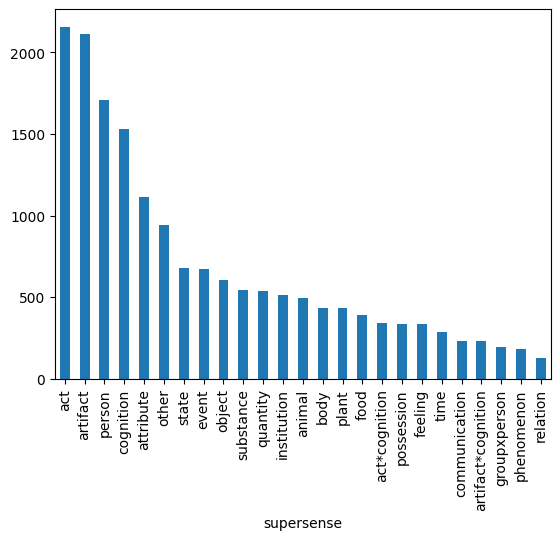

In [ ]:
df['supersense'].value_counts().plot(kind='bar')

### Distribution of hypersenses

In [ ]:
supersenses = df['supersense'].unique()
super2hyper = {'artifact': 'inanimate',
               'body': 'inanimate',
               'food': 'inanimate',
               'object': 'inanimate',
               'plant': 'inanimate',
               'substance': 'inanimate',
               'act':  'dynamic_situation',
               'event': 'dynamic_situation',
               'phenomenon': 'dynamic_situation',
               'animal': 'animate',
               'person': 'animate',
               'groupxperson': 'animate',
               'cognition': 'information',
               'communication': 'information',
               'quantity': 'quantity',
               'attribute': 'stative_situation',
               'feeling': 'stative_situation',
               'relation': 'stative_situation',
               'state': 'stative_situation',
               'time': 'time',
               'possession': 'possession',
               'institution': 'institution',
               'act*cognition': 'dynamic_situation*information',
               'artifact*cognition': 'inanimate*information',
               'other': 'other',
               }


<Axes: xlabel='hypersense'>

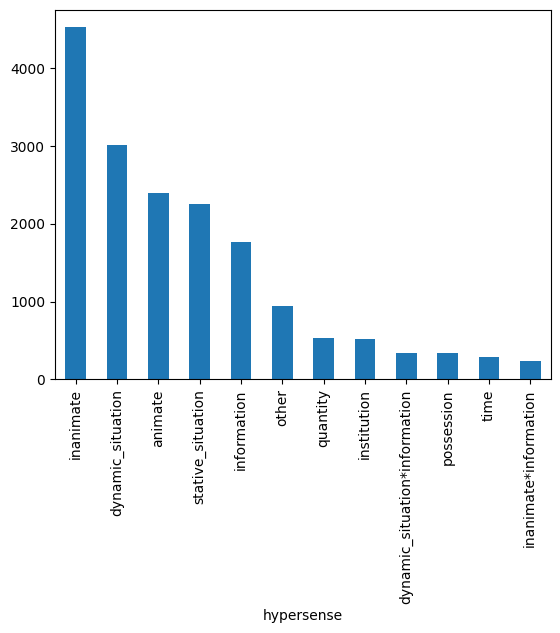

In [ ]:
df['hypersense'] = df['supersense'].map(super2hyper)
df['hypersense'].value_counts().plot(kind='bar')

### Distribution of labels across the data subsets (splits)

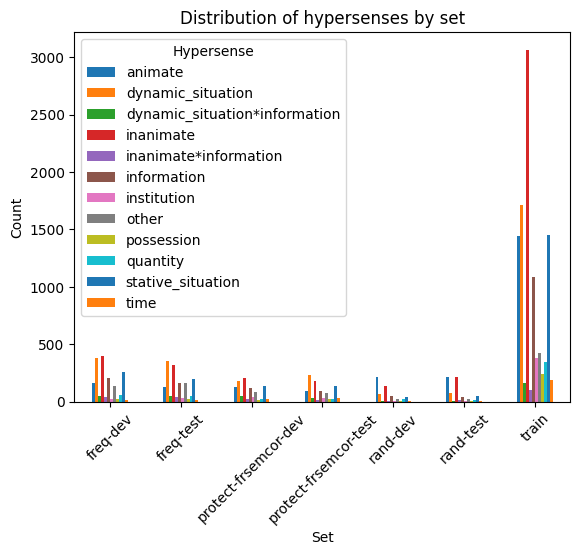

In [ ]:
# PB: note the distribution in the training set, dev and test sets are quite different

df.groupby('set')['hypersense'].value_counts().unstack().plot(kind='bar')
plt.title('Distribution of hypersenses by set')
plt.xlabel('Set')
plt.ylabel('Count')
plt.xticks(rotation=45)
plt.legend(title='Hypersense')
plt.show()

## Classifiers


You will compare
1. Using a causal model with in-context learning (ICL)
  - you will use a small LLM (maximum 8B), fine-tuned for instructions
    - either use a mini model (< 2G) on google colab
    - or a quantized version of a little larger model (≤ 8B)
      - e.g. the bitsandbytes module on huggingface can help you : https://huggingface.co/docs/transformers/main/quantization/bitsandbytes
      - there are also some pre-quantized models e.g. by unsloth.ai (faster to download, and you save the time to quantize) : e.g. https://huggingface.co/unsloth/mistral-7b-bnb-4bit
    - https://llm-explorer.com/static/llm-leaderboards/
    - explain how you chose the model
    - a possible leaderboard for evaluation in languages other than English:
      - https://huggingface.co/spaces/Eurolingua/european-llm-leaderboard
  - or use the huggingface API to run the model on HF's servers
    - cf. https://huggingface.co/docs/huggingface_hub/guides/inference
    - (I don't know the exact amount of inference you can do with the free version)
  - Look for prompts tested in the literature to perform text classification, and adapt it to the task
    - e.g. is it better to write a prompt in English, and leave the labels in English? Or do everything in French?
  - How many examples for ICL? etc...

2. Parameter-efficient fine-tuning of a (quantized) causal model on the full training set
  - see the numerous examples on the web for using LoRA or QLoRA in a google colab
  - possible comparison: in which module of the model's architecture to add the LoRA mechanism?
  - possible comparison: simply sticking to the text generation task, versus using a classification head (easy specification e.g. in the LoraConfig of the peft huggingface module)

In both cases, during the inference phase (generation), a possible comparison is to let the model generate the hypersense label, or to fetch the log-probability of labels for the position after the prompt (requires using single-tokenized labels).

3. Optional: full fine-tuning of an encoder-only French model
   - e.g. FlauBERT or CamemBERT (these are small models compared to current generative models)
   - add a classification head on top of the pre-trained encoder model, and do a full training on our data



## Methodology

The dataset comprises a training set (cf. column "set" of the dataframe), and several dev and test sets.

In all your work **you will ignore the "protect-frsemcor" instances**.
You will use **rand-dev** for tuning hyperparameters (including the form of prompts, the nb of demonstrations in ICL etc...), and report your FINAL results on **freq-test** and **rand-test**, for the two main methods (ICL and LoRA fine-tuning).

In your experiments,
- **figure out whether the lemma is useful to provide as input**, on top of the sense definition.
- perform sound comparisons of your various settings (choose some characteristics you want to compare)



## How your project will be evaluated

You will turn in a PDF file, with a report on your methodology, experiments, problems encountered, results etc...
- you should point to your colab within the pdf report
- do not create the pdf from the colab directly, as it provides reports that are difficult to read.

It is likely that you will use code seen on the web or generated via a LLM. Show me you perfectly master your code (no useless instructions, appropriate comments ...).

The overall performance is not what matters most, in particular because it would be a waste of compute energy to make too many experiments.

You project will be evaluated based on
- sound methodology
- clear and commented code
- well presented and discussed results
- error analysis (trying to figure out what kind of instances are badly classified and why?)

Bonus for new ideas on top of what is suggested above.

# Our Implementation     

## PART 0 Our Implementation: Dataset Inspection and Preparation

**Dataset Inspection**

Although some information about the dataset has already been provided above, we take a closer look here to better understand its structure. We check the number of examples, available columns, dataset splits, and missing values. We also look at a few examples to get a clearer idea of what the data looks like.

In [ ]:
from IPython.display import display

required_columns = ["lemma", "definition", "supersense", "hypersense", "set"]

# Check dataset structure
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

# Check dataset splits
print("-" * 20)
print("Dataset splits:")
print(df["set"].value_counts())

# Check missing values
print("-" * 20)
print("Missing values:")
print(df[required_columns].isna().sum())

# Preview examples
print("-" * 20)
print("Sample examples:")
display(df[required_columns].head())

Dataset shape: (17159, 8)
Columns: ['sense_id', 'entry_id', 'lemma', 'nb_occ_lemma_frsemcor', 'supersense', 'set', 'definition', 'hypersense']
--------------------
Dataset splits:
set
train                    10604
freq-dev                  1760
freq-test                 1521
protect-frsemcor-dev      1041
protect-frsemcor-test      985
rand-test                  678
rand-dev                   570
Name: count, dtype: int64
--------------------
Missing values:
lemma          0
definition    23
supersense     0
hypersense     0
set            0
dtype: int64
--------------------
Sample examples:


,lemma,definition,supersense,hypersense,set
0,esquerme,Plante potagère.,plant,inanimate,rand-test
1,béruguette,Variété d’olive allongée à pulpe ferme.,food,inanimate,rand-dev
2,agroécologie,Pratique ou mode de production agricole appliq...,act,dynamic_situation,rand-test
3,webcaméra,Synonyme de webcam.,artifact,inanimate,rand-test
4,Reguinois,"Habitant de Réguiny, commune française située ...",person,animate,rand-dev


**Data Preparation and Splitting**

The label distributions have already been visualized above, here we briefly examine them again here for reference. We also keep only the four dataset splits needed for our experiments: train, rand-dev, rand-test, and freq-test, and create separate DataFrames for each split.

We also examine the number and distribution of supersense and hypersense labels.

In [ ]:
# Select dataset splits
selected_splits = ["train", "rand-dev", "rand-test", "freq-test"]
data = df[df["set"].isin(selected_splits)].copy()

# Create dataset splits
train = data[data["set"] == "train"].copy()
dev = data[data["set"] == "rand-dev"].copy()
rand_test = data[data["set"] == "rand-test"].copy()
freq_test = data[data["set"] == "freq-test"].copy()

# Dataset sizes
print("Dataset sizes:")
print(data["set"].value_counts())


# Classification labels
supersense_labels = sorted(data["supersense"].dropna().unique())
hypersense_labels = sorted(data["hypersense"].dropna().unique())
print("-" * 20)
print(f"Supersense classes ({len(supersense_labels)}):", supersense_labels)
print(f"Hypersense classes ({len(hypersense_labels)}):", hypersense_labels)

# Overall label distributions
print("-" * 20)
print("Supersense distribution:")
print(df["supersense"].value_counts())

print("-" * 20)
print("Hypersense distribution:")
print(df["hypersense"].value_counts())

Dataset sizes:
set
train        10604
freq-test     1521
rand-test      678
rand-dev       570
Name: count, dtype: int64
--------------------
Supersense classes (25): ['act', 'act*cognition', 'animal', 'artifact', 'artifact*cognition', 'attribute', 'body', 'cognition', 'communication', 'event', 'feeling', 'food', 'groupxperson', 'institution', 'object', 'other', 'person', 'phenomenon', 'plant', 'possession', 'quantity', 'relation', 'state', 'substance', 'time']
Hypersense classes (12): ['animate', 'dynamic_situation', 'dynamic_situation*information', 'inanimate', 'inanimate*information', 'information', 'institution', 'other', 'possession', 'quantity', 'stative_situation', 'time']
--------------------
Supersense distribution:
supersense
act                   2156
artifact              2113
person                1707
cognition             1530
attribute             1116
other                  945
state                  682
event                  674
object                 607
substance  

## PART 1 Shared Setup

Both experiments use the same dataset splits and base model.

Due to limited GPU resources, we conducted the ICL and QLoRA experiments across separate Google Colab sessions and accounts. We saved the predictions and training results to Google Drive, then brought them together in this notebook.

By default, all execution switches are set to `False`. The notebook loads the saved results without requiring a GPU or rerunning the models. To reproduce the experiments from scratch, the corresponding GPU switches can be enabled.

The ICL and QLoRA results are stored in separate folders (`ICL/` and `QLoRA/`), while the evaluation and comparison are performed in this notebook.

We select Qwen3-4B-Instruct-2507, a pre-quantized 4-bit model, for both ICL and QLoRA experiments.

In [ ]:
from pathlib import Path
import pandas as pd
from google.colab import drive

drive.mount("/content/drive")

# Saved experiment results
ICL_DIR = Path("/content/drive/MyDrive/M2-pariscite/currentnlp/Lab1/ICL")
LORA_DIR = Path("/content/drive/MyDrive/M2-pariscite/currentnlp/Lab1/QLoRA")
output_dir = str(ICL_DIR)

# Execution settings — use saved results by default
RUN_GPU = False         # Enable GPU-dependent model loading, training, or inference.
RUN_TRAINING = False    # Rerun QLoRA training when enabled (requires RUN_GPU=True).
RUN_PREDICTION = False  # Generate new predictions instead of using saved CSV files (requires RUN_GPU=True).

# Model settings
model_identifier = "unsloth/Qwen3-4B-Instruct-2507-bnb-4bit"
classification_target = "hypersense"
random_seed = 42

# Load saved predictions without running inference
def read_cached_csv(path):
    """Read predictions from an existing CSV file."""
    return pd.read_csv(path)

print("Mode:", "GPU" if RUN_GPU else "Saved results (CPU)")
print("ICL:", ICL_DIR)
print("QLoRA:", LORA_DIR)

Mounted at /content/drive
Mode: Saved results (CPU)
ICL: /content/drive/MyDrive/M2-pariscite/currentnlp/Lab1/ICL
QLoRA: /content/drive/MyDrive/M2-pariscite/currentnlp/Lab1/QLoRA


## PART 2 In-Context Learning (ICL)



### 2.1 ICL Methodology

We first compare 0-, 3-, and 6-shot prompting, with and without lemma, on `rand-dev`. Since the initial results show no consistent trend, we add a 12-shot follow-up experiment.

We then select the best configuration for final testing on `rand-test` and `freq-test`.

In [ ]:
# Install ICL libraries only if training or adapter inference is requested.
if RUN_GPU and (RUN_TRAINING or RUN_PREDICTION):
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "--progress-bar", "on", "-v",
                    "bitsandbytes>=0.46.1", "peft", "datasets", "accelerate",
                    "transformers>=4.55,<5"], check=True)
else:
    print("ICL: saved-results mode; model packages are not needed.")

ICL: saved-results mode; model packages are not needed.


In [ ]:
import os
import torch
import pandas as pd
from google.colab import drive
from sklearn.metrics import accuracy_score, f1_score
if RUN_GPU:
    from transformers import AutoTokenizer, AutoModelForCausalLM

In [ ]:
# Drive was mounted in the shared setup above.
output_dir = str(ICL_DIR)
os.makedirs(output_dir, exist_ok=True)
print("ICL results directory:", output_dir)
print("GPU:", torch.cuda.get_device_name(0) if RUN_GPU and torch.cuda.is_available() else "Not used")

ICL results directory: /content/drive/MyDrive/M2-pariscite/currentnlp/Lab1/ICL
GPU: Not used


### 2.2 Demonstration Selection

We select demonstrations from the training set and keep them fixed for each shot count. This allows us to compare prompts with and without lemma information using the same examples.

In [ ]:
# Select 6 demonstrations from different hypersense classes
demos_path = ICL_DIR / "selected_demonstrations.csv"

if demos_path.exists():
    demos = pd.read_csv(demos_path)
else:
    demos = (
        train.dropna(subset=["lemma", "definition", "hypersense"])
        .groupby("hypersense").sample(n=1, random_state=random_seed) # randomly select one example from each hypersense
        .sample(n=6, random_state=random_seed) # then randomly select 6 examples from the 12 selected above
        [["lemma", "definition", "hypersense"]]
        .reset_index(drop=True)
    )
    demos.to_csv(demos_path, index=False)

display(demos)

,lemma,definition,hypersense
0,pénurie,Extrême disette.,stative_situation
1,millième,"Unité de division de la copropriété, le total ...",quantity
2,journaliste,"Personne qui fait, qui rédige un journal, qui ...",animate
3,centime,La centième partie d’un euro.,possession
4,jérémiade,Plainte fréquente et importune.,information
5,amendement,Modification d’un jugement.,dynamic_situation*information


### 2.3 Prompt Construction

In [ ]:
def build_prompt(lemma: str, definition: str, include_lemma: bool, examples: pd.DataFrame) -> str:
    """
    Build a classification prompt with optional lemmas and demonstrations.
    Args:
        lemma: French word to classify.
        definition: Definition of the word sense.
        include_lemma: Whether to include the lemma in the prompt.
        examples: Training demonstrations (empty for zero-shot).
    Returns:
        str: Complete prompt text.
    """

    labels = ", ".join(hypersense_labels)

    # Format one word sense, including the lemma only when requested
    def format_input(word, meaning):
        lemma_line = f"Lemma: {word}\n" if include_lemma else ""
        return f"{lemma_line}Definition: {meaning}"

    # Task instruction
    prompt = (
        "Your task is to assign a hypersense category to the following French word sense.\n"
        f"Choose one category from the following list: {labels}\n"
        "Provide only the category name. Do not include any explanation.\n"
    )

    # Add labeled demonstrations for few-shot prompting
    if not examples.empty:
        prompt += "\nExamples:\n"
        for _, example in examples.iterrows():
            prompt += (
                f"\n{format_input(example['lemma'], example['definition'])}\n"
                f"Category: {example['hypersense']}\n"
            )
    # Add the word sense to classify (without its correct label)
    prompt += f"\nNow classify the following word sense.\n{format_input(lemma, definition)}\nCategory:"

    return prompt

In [ ]:
# Preview a 3-shot prompt with lemmas
example = dev.iloc[0]

sample_prompt = build_prompt(
    lemma=example["lemma"],
    definition=example["definition"],
    include_lemma=True,
    examples=demos.head(3)
)

print(sample_prompt)

Your task is to assign a hypersense category to the following French word sense.
Choose one category from the following list: animate, dynamic_situation, dynamic_situation*information, inanimate, inanimate*information, information, institution, other, possession, quantity, stative_situation, time
Provide only the category name. Do not include any explanation.

Examples:

Lemma: pénurie
Definition: Extrême disette.
Category: stative_situation

Lemma: millième
Definition: Unité de division de la copropriété, le total précisé dans l’état descriptif de division n’étant pas forcément 1000.
Category: quantity

Lemma: journaliste
Definition: Personne qui fait, qui rédige un journal, qui travaille, à la rédaction d’un journal.
Category: animate

Now classify the following word sense.
Lemma: béruguette
Definition: Variété d’olive allongée à pulpe ferme.
Category:


In [ ]:
# Preview a 3-shot prompt without lemmas
example = dev.iloc[0]

sample_prompt = build_prompt(
    lemma=example["lemma"],
    definition=example["definition"],
    include_lemma=False,
    examples=demos.head(3)
)

print(sample_prompt)

Your task is to assign a hypersense category to the following French word sense.
Choose one category from the following list: animate, dynamic_situation, dynamic_situation*information, inanimate, inanimate*information, information, institution, other, possession, quantity, stative_situation, time
Provide only the category name. Do not include any explanation.

Examples:

Definition: Extrême disette.
Category: stative_situation

Definition: Unité de division de la copropriété, le total précisé dans l’état descriptif de division n’étant pas forcément 1000.
Category: quantity

Definition: Personne qui fait, qui rédige un journal, qui travaille, à la rédaction d’un journal.
Category: animate

Now classify the following word sense.
Definition: Variété d’olive allongée à pulpe ferme.
Category:


In [ ]:
# Preview a zero-shot prompt without lemmas
prompt_1 = build_prompt(
    lemma=example["lemma"],
    definition=example["definition"],
    include_lemma=False,
    examples=demos.head(0)
)
print(prompt_1)

Your task is to assign a hypersense category to the following French word sense.
Choose one category from the following list: animate, dynamic_situation, dynamic_situation*information, inanimate, inanimate*information, information, institution, other, possession, quantity, stative_situation, time
Provide only the category name. Do not include any explanation.

Now classify the following word sense.
Definition: Variété d’olive allongée à pulpe ferme.
Category:


### 2.4 Original Label Generation & Prediction Functions

The model's original configuration uses BF16 (BFloat16) for computation.
However, the Colab T4 GPU does not natively support BF16, so we use FP16 instead.

**References:**
- [Qwen3-4B-Instruct-2507 Model Card](https://huggingface.co/Qwen/Qwen3-4B-Instruct-2507): Model information and configuration.
- [Hugging Face Chat Templates](https://huggingface.co/docs/transformers/main/en/chat_templating): Documentation on formatting messages for chat models.

In [ ]:
if RUN_GPU:
    import torch
    import bitsandbytes as bnb
    from transformers import AutoTokenizer, AutoModelForCausalLM

    # Load the pre-quantized model
    tokenizer = AutoTokenizer.from_pretrained(model_identifier)
    model = AutoModelForCausalLM.from_pretrained(
        model_identifier, device_map="auto", dtype=torch.float16
    )

    # Use FP16 computation on T4 GPUs
    if torch.cuda.is_available() and torch.cuda.get_device_capability(0)[0] < 8:
        for layer in model.modules():
            if isinstance(layer, bnb.nn.Linear4bit):
                layer.compute_dtype = torch.float16

    model.eval()
    print("Model loaded:", model_identifier)
else:
    print("Qwen loading skipped: saved ICL predictions.")


Qwen loading skipped: saved ICL predictions.


**Original Label Generation**

We use label generation to classify French word senses into hypersense categories. The model receives a prompt containing the definition, optionally the lemma, and few-shot demonstrations.

We use Greedy Decoding (`do_sample=False`). At each step, the model selects the token with the highest predicted probability. This process is repeated token by token until generation stops.

We set `max_new_tokens=24` as a practical limit to prevent the model from generating unnecessarily long responses. This value was not specifically optimized. So there is enough space for hypersense labels that may consist of multiple tokens, such as `dynamic_situation`.

Since the generated output may not match one of the 12 predefined hypersense labels, we take the first line, remove surrounding whitespace and punctuation, and check whether it matches a valid label. Otherwise, the prediction is marked as `INVALID`.

These generation parameters are described in the [Hugging Face Transformers documentation](https://huggingface.co/docs/transformers/main_classes/text_generation).

In [ ]:
@torch.inference_mode()
def predict_label(prompt: str) -> tuple[str, str]:
    """Generate a hypersense label and return the prediction and raw output."""

    # Follow the Qwen inference format provided in the Hugging Face documentation.
    # Apply the chat template, tokenize the prompt, and move the inputs to the model's device.
    inputs = tokenizer.apply_chat_template(
        [{"role": "user", "content": prompt}],
        tokenize=True, add_generation_prompt=True,
        return_dict=True, return_tensors="pt"
    ).to(model.device)

    # Generate a prediction
    outputs = model.generate(
        **inputs, max_new_tokens=24, do_sample=False,
        pad_token_id=tokenizer.eos_token_id
    )

    # model.generate() returns both the original input tokens and the newly generated tokens.
    # Remove the input prompt tokens and keep only the newly generated tokens.
    # Convert these token IDs back into readable text, skipping special tokens.
    # Remove any leading or trailing whitespace.
    raw_output = tokenizer.decode(
        outputs[0][inputs["input_ids"].shape[-1]:],
        skip_special_tokens=True
    ).strip()

    # Take the first line of the generated output and remove surrounding spaces and punctuation.
    # Keep the result only if it exactly matches a valid hypersense label; otherwise, mark it as INVALID.
    pred_label = raw_output.splitlines()[0].strip(" `\"'.,:") if raw_output else ""
    pred_label = pred_label if pred_label in hypersense_labels else "INVALID"

    return pred_label, raw_output

The run_icl() function classifies examples using the selected ICL configuration.

It first loads any previously saved predictions and skips completed examples to avoid repeated inference. For the remaining examples, it builds prompts, generates predictions, and saves the results to CSV every 10 predictions, allowing the experiment to resume if interrupted

In [ ]:
def run_icl(dataset: pd.DataFrame, split_name: str, n_shots: int,
            include_lemma: bool, max_rows: int | None = None) -> pd.DataFrame:
    """
    Run ICL classification and save predictions as a CSV file.
    Args:
        dataset: Dataset to classify (dev or test).
        split_name: Dataset name, used for the output filename.
        n_shots: Number of demonstrations included in the prompt.
        include_lemma: Whether to include lemmas in the prompt.
        max_rows: Optional limit on the number of examples to classify.
    Returns:
        pd.DataFrame: Predictions, true labels, and raw model outputs.
    """

    # Remove examples missing a lemma, definition, or true label.
    # Reset the index so each example has a consistent row_id.
    eval_data = dataset.dropna(subset=["lemma", "definition", "hypersense"]).reset_index(drop=True)

    # Optionally limit the number of examples for a small test run.
    if max_rows is not None:
        eval_data = eval_data.head(max_rows)

    # Use the first n_shots demonstrations selected from the training set.
    examples = demos.head(n_shots)

    # Build a filename identifying the dataset, shot count, and input format.
    # Load existing predictions and collect their row_ids to avoid running them again.
    input_type = "lemma" if include_lemma else "definition"
    results_path = f"{output_dir}/icl_v1_{split_name}_{n_shots}shot_{input_type}.csv"
    results = pd.read_csv(results_path).to_dict("records") if os.path.exists(results_path) else []
    completed_ids = {row["row_id"] for row in results}

    # Process each example, skipping those already saved in the CSV.
    for row_id, row in eval_data.iterrows():
        if row_id in completed_ids:
            continue

        # Build the prompt and generate a hypersense prediction.
        prompt = build_prompt(row["lemma"], row["definition"], include_lemma, examples)
        pred_label, raw_output = predict_label(prompt)

        # Keep the original input, correct label, prediction, and raw model response.
        results.append({
            "row_id": row_id,
            "lemma": row["lemma"],
            "definition": row["definition"],
            "true_label": row["hypersense"],
            "pred_label": pred_label,
            "raw_output": raw_output
        })

        # Save every 10 predictions so progress is not lost if Colab disconnects.
        if len(results) % 10 == 0:
            pd.DataFrame(results).to_csv(results_path, index=False)
            print(f"Saved {len(results)}/{len(eval_data)} predictions", end="\r")

    # Sort predictions by row_id, save the final CSV, and return the results.
    results_df = pd.DataFrame(results).sort_values("row_id")
    results_df.to_csv(results_path, index=False)

    print(f"\n{split_name} | {n_shots}-shot | {input_type}: {len(results_df)} saved")
    return results_df

In [ ]:
def load_or_run_icl(dataset, split_name, n_shots, include_lemma, max_rows=None):
    """Run ICL inference if GPU is enabled; otherwise load saved predictions."""

    # Run the original inference function when GPU is enabled
    if RUN_GPU:
        return run_icl(dataset, split_name, n_shots, include_lemma, max_rows)

    # Find the CSV corresponding to the experiment configuration
    suffix = "lemma" if include_lemma else "definition"
    path = f"{output_dir}/icl_v1_{split_name}_{n_shots}shot_{suffix}.csv"

    # Load saved predictions without calling Qwen
    results = read_cached_csv(path)

    # Optionally select only the first max_rows predictions
    if max_rows is not None:
        results = results.sort_values("row_id").head(max_rows)

    print(f"{split_name} | {n_shots}-shot | {suffix}: {len(results)} cached")
    return results

### 2.5 Experiment 1: Initial 0/3/6-shot Development Experiments

We first vary the number of demonstrations (0, 3, 6) and compare **definition only** with **lemma + definition** on `rand-dev`. The pilot and main configurations below retain the original code and settings.

In [ ]:
# Test 10 examples for both zero-shot settings
pilot_a = load_or_run_icl(dev, "dev", 0, False, max_rows=10)
pilot_b = load_or_run_icl(dev, "dev", 0, True, max_rows=10)

# Compare predictions
comparison = pd.DataFrame({
    "True label": pilot_a["true_label"].values,
    "Definition only": pilot_a["pred_label"].values,
    "With lemma": pilot_b["pred_label"].values
})

display(comparison)

dev | 0-shot | definition: 10 cached
dev | 0-shot | lemma: 10 cached


,True label,Definition only,With lemma
0,inanimate,inanimate,inanimate*information
1,animate,inanimate*information,inanimate*information
2,animate,inanimate*information,inanimate*information
3,inanimate,inanimate*information,inanimate
4,animate,information,information
5,inanimate,inanimate,inanimate
6,information,inanimate,inanimate*information
7,other,dynamic_situation,dynamic_situation
8,animate,inanimate,inanimate
9,information,inanimate,inanimate


In [ ]:
# Run all six configurations on rand-dev
experiment_settings = [(0, False), (0, True), (3, False), (3, True), (6, False), (6, True)]

dev_results = {}

for n_shots, include_lemma in experiment_settings:
    experiment_name = f"{n_shots}shot_{'lemma' if include_lemma else 'definition'}"
    dev_results[experiment_name] = load_or_run_icl(dev, "dev", n_shots, include_lemma)

dev | 0-shot | definition: 570 cached
dev | 0-shot | lemma: 570 cached
dev | 3-shot | definition: 570 cached
dev | 3-shot | lemma: 570 cached
dev | 6-shot | definition: 570 cached
dev | 6-shot | lemma: 570 cached


After running the initial ICL experiments on `rand-dev`, we evaluate their performance using Accuracy, Macro-F1, and the number of invalid predictions.

We also include two simple baselines for comparison:
- **Random Baseline:** randomly selects one of the 12 hypersense labels.
- **Majority Class Baseline:** always predicts the most frequent label in the training set.

These baselines help us assess whether ICL performs better than simple prediction strategies.

In [ ]:
from sklearn.metrics import accuracy_score, f1_score

def calculate_metrics(results: pd.DataFrame) -> dict:
    """
    Calculate classification metrics from saved predictions.
    Args:
        results: DataFrame returned by run_icl() or load_or_run_icl(),
             containing true_label and pred_label columns.
    Returns:
        dict: Accuracy, Macro-F1 across the 12 hypersense classes,
              and the number of invalid predictions.
    """

    true_labels, pred_labels = results["true_label"], results["pred_label"]

    return {
        "Accuracy": accuracy_score(true_labels, pred_labels),
        "Macro-F1": f1_score(true_labels, pred_labels, labels=hypersense_labels, average="macro", zero_division=0),
        "Invalid": (~pred_labels.isin(hypersense_labels)).sum()
    }

In [ ]:
# Compare random and majority-class baselines with ICL experiments on rand-dev
import numpy as np

# Use the same evaluation examples as the ICL experiments
eval_data = dev.dropna(subset=["lemma", "definition", "hypersense"]).reset_index(drop=True)

# Random: randomly choose a label from the 12 categories.
# Majority Class: always predict the most frequent label in the training set.
baselines = {
    "Random": np.random.default_rng(random_seed).choice(hypersense_labels, len(eval_data)),
    "Majority Class": [train["hypersense"].value_counts().idxmax()] * len(eval_data)
}

# Calculate Accuracy, Macro-F1, and Invalid for baselines and ICL experiments
dev_summary = pd.DataFrame(
    # Evaluate each baseline
    ## **calculate_metrics(): Unpack the returned dictionary into the current dictionary.
    [{"Experiment": name, **calculate_metrics(pd.DataFrame({
            "true_label": eval_data["hypersense"],
            "pred_label": predictions
        }))}
        # Iterate over baseline names and predictions
        for name, predictions in baselines.items()]
    +
    # Evaluate each ICL experiment
    [{"Experiment": name, **calculate_metrics(results)}
        # Results already contain true_label and pred_label
        for name, results in dev_results.items()]
).round(4)

# Display and save the development results
display(dev_summary)
dev_summary.to_csv(f"{output_dir}/icl_dev_summary.csv", index=False)

,Experiment,Accuracy,Macro-F1,Invalid
0,Random,0.0825,0.0571,0
1,Majority Class,0.2386,0.0321,0
2,0shot_definition,0.4035,0.2736,6
3,0shot_lemma,0.3982,0.2835,14
4,3shot_definition,0.4825,0.2999,4
5,3shot_lemma,0.5211,0.3512,4
6,6shot_definition,0.4509,0.3009,3
7,6shot_lemma,0.4316,0.3617,4


Preliminary Observations and Motivation for the Follow-up Experiment

Our initial experiments on rand-dev showed that more demonstrations did not always lead to better performance.
- The 3-shot + lemma configuration achieved the highest Accuracy (0.5211), while 6-shot + lemma achieved the highest Macro-F1 (0.3617), but with lower Accuracy (0.4316).
- ncluding the lemma improved Macro-F1 in all three shot settings, but its effect on Accuracy was inconsistent.

Since the results did not show a clear trend, we decided to test 12-shot as well, to further explore whether using more demonstrations could improve classification performance. We tested both definition-only and lemma + definition inputs on rand-dev.

### 2.6 Experiment 2: Follow-up 12-shot Experiment

Based on the initial results, we added a 12-shot setting to further examine the effect of using more demonstrations.

However, using more demonstrations also introduces examples from additional hypersense categories, which may influence the results.

We extend the original 6 demonstrations to 12 by adding one training example from each hypersense category not yet represented.

We then evaluate both 12-shot configurations on `rand-dev` and restore the original 6 demonstrations afterward.

In [ ]:
# Extend demonstrations from 6 to 12
original_demos = demos.copy()

extra_demos = (
    train[
        ~train["hypersense"].isin(original_demos["hypersense"])
    ]
    .dropna(subset=["lemma", "definition", "hypersense"])
    .groupby("hypersense")
    .sample(n=1, random_state=random_seed)
    [["lemma", "definition", "hypersense"]]
    .reset_index(drop=True)
)

# Combine the original 6 demos with 6 additional demos
demos = pd.concat([original_demos, extra_demos], ignore_index=True)


# Save the 12 demonstrations
demos.to_csv(f"{output_dir}/selected_demonstrations_12shot.csv", index=False)

# Run 12-shot experiments on rand-dev
try:
    for include_lemma in [False, True]:
        name = f"12shot_{'lemma' if include_lemma else 'definition'}"
        dev_results[name] = load_or_run_icl(dev, "dev", 12, include_lemma)
finally:
    demos = original_demos # restore the original 6 demos, even if an error occurs

# Evaluate the two new configurations
summary_12shot = pd.DataFrame([
    {"Experiment": name, **calculate_metrics(dev_results[name])}
    for name in ["12shot_definition", "12shot_lemma"]
]).round(4)

display(summary_12shot)

dev | 12-shot | definition: 570 cached
dev | 12-shot | lemma: 570 cached


,Experiment,Accuracy,Macro-F1,Invalid
0,12shot_definition,0.4351,0.3438,2
1,12shot_lemma,0.4491,0.3637,7


### 2.7 Optional Experiment: Generation vs. Label Log-Probability

In greedy label generation, the model predicts tokens one by one from its entire vocabulary. Although the prompt asks it to output only a hypersense label, it may generate additional text or an answer outside the 12 categories. We therefore explore another inference method: instead of generating an answer, we directly compare the probabilities of the candidate labels and select the most likely one.

The lab instructions suggest comparing label log-probabilities **at the position immediately after the prompt**, which requires single-token labels. However, some of our original hypersense labels contain multiple tokens. For example, `dynamic_situation` is split into four tokens by the Qwen tokenizer. Its probability cannot be obtained from a single next-token prediction; calculating it would require scoring the entire token sequence. To follow the method described in the instructions, we replace the 12 hypersense names with **single-token codes (A–L)**. The prompt includes the mapping between each code and its original category, and the demonstrations use these codes as their answers.

We compare two inference methods using the same **3-shot + lemma configuration** on `rand-dev`. Both use the same model, prompt, category mapping, and three demonstrations. In **greedy label generation**, the model generates an answer normally, and we extract the predicted code and convert it back to its original hypersense label. In **label log-probability scoring**, we obtain the logits for the next token after the prompt, apply log-softmax, and compare the scores of the 12 candidate codes. The code with the highest score is selected as the prediction. Since the choice is restricted to A–L, this method always returns a valid category.


In [ ]:
# Check how many tokens each original hypersense label contains
if RUN_GPU:
    for label in hypersense_labels:
        token_ids = tokenizer.encode(
            label,
            add_special_tokens=False
        )
        print(f"{label}: {len(token_ids)} token(s), IDs: {token_ids}")
else:
    print("Tokenization check skipped (no model loaded).")

Tokenization check skipped (no model loaded).


Label mapping

In [ ]:
# Map hypersense labels to A-L codes
codes = list("ABCDEFGHIJKL")
code_to_label = dict(zip(codes, hypersense_labels))
label_to_code = {label: code for code, label in code_to_label.items()}

# Use the same 3 demonstrations as the original ICL experiment
coded_demos = pd.read_csv(ICL_DIR / "selected_demonstrations.csv").head(3)

# Check that each code is a single token
code_token_ids = {}
if RUN_GPU:
    for code, label in code_to_label.items():
        ids = tokenizer.encode(code, add_special_tokens=False)
        if len(ids) != 1:
            raise ValueError(f"{code} is not a single token")
        code_token_ids[code] = ids[0]
        print(f"{code} -> {label}: {ids}")

    # Check whether prefixes affect tokenization
    for text in ["A", " A", "\nA"]:
        print(repr(text), tokenizer.encode(text, add_special_tokens=False))

Prompt and prediction

In [ ]:
import json

# Build a 3-shot prompt using A-L category codes
def build_coded_prompt(lemma: str, definition: str) -> str:
    mapping = ", ".join(f"{code} = {label}" for code, label in code_to_label.items())
    prompt = (
        "Your task is to assign a hypersense category to the following French word sense.\n"
        f"Choose one category code from the following list: {mapping}\n"
        "Provide only the category code (A-L). Do not include any explanation.\n"
        "\nExamples:\n"
    )

    # Use the same demonstrations, replacing labels with their codes
    for _, ex in coded_demos.iterrows():
        prompt += (
            f"\nLemma: {ex['lemma']}\n"
            f"Definition: {ex['definition']}\n"
            f"Category: {label_to_code[ex['hypersense']]}\n"
        )

    prompt += (
        "\nNow classify the following word sense.\n"
        f"Lemma: {lemma}\nDefinition: {definition}\nCategory:"
    )
    return prompt


@torch.inference_mode()
def predict_coded_label(prompt: str, method: str) -> tuple[str, str, str]:
    """
    Predict a hypersense label using A-L category codes.
    Args:
        prompt: The classification prompt.
        method: Inference method:
            - "generation": Generate a code using greedy decoding.
            - "logprob": Select the code with the highest next-token log-probability.

    Returns: (prediction, code, details):
            prediction: Original hypersense label or "INVALID".
            code: Predicted A-L code.
            details: Generated text or JSON log-probability scores.
    """
    # Prepare identical model inputs for both inference methods
    inputs = tokenizer.apply_chat_template(
        [{"role": "user", "content": prompt}],
        tokenize=True, add_generation_prompt=True,
        return_dict=True, return_tensors="pt"
    ).to(model.device)

    if method == "generation":
        # Greedy generation from the full vocabulary
        outputs = model.generate(
            **inputs, max_new_tokens=8, do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )
        raw = tokenizer.decode(
            outputs[0][inputs["input_ids"].shape[-1]:],
            skip_special_tokens=True
        ).strip()

        # Extract the code and check whether it is valid
        code = raw.splitlines()[0].strip(" `\"'.,:") if raw else ""
        return code_to_label.get(code, "INVALID"), code, raw

    if method == "logprob":
        # Get next-token log-probabilities instead of generating text
        logits = model(**inputs).logits[0, -1, :].float()
        log_probs = torch.log_softmax(logits, dim=-1)

        # Score only the 12 candidate codes
        scores = {
            code: log_probs[token_id].item()
            for code, token_id in code_token_ids.items()
        }
        code = max(scores, key=scores.get)
        return code_to_label[code], code, json.dumps(scores)

In [ ]:
# Load saved predictions or complete missing ones
def run_coded_icl(method: str) -> pd.DataFrame:
    """
    Run or load A-L classification predictions on rand-dev.
    Args:
        method: Inference method:
            - "generation": Greedy label generation.
            - "logprob": Next-token log-probability scoring.
    Returns:
        pd.DataFrame: Predictions, true labels, and model outputs.
    Notes:
        Reuses saved CSV predictions and only runs missing examples
        when RUN_GPU is True.
    """
    if method not in ["generation", "logprob"]:
        raise ValueError(f"Unknown method: {method}")

    path = ICL_DIR / f"icl_code_v1_dev_3shot_lemma_{method}.csv"
    data = dev.dropna(subset=["lemma", "definition", "hypersense"]).reset_index(drop=True)

    # Reuse existing predictions
    rows = read_cached_csv(path).to_dict("records") if path.exists() else []
    completed = {int(row["row_id"]) for row in rows}

    # Check saved predictions
    if len(completed) != len(rows) or any(i < 0 or i >= len(data) for i in completed):
        raise ValueError(f"Invalid or duplicate row IDs in {path}")

    for row in rows:
        if row["true_label"] != data.iloc[int(row["row_id"])]["hypersense"]:
            raise ValueError(f"Cached labels do not match rand-dev: {path}")

    # Only run inference for missing examples
    if len(completed) < len(data):
        if not RUN_GPU:
            raise RuntimeError(f"Incomplete predictions: {path}")

        for row_id, row in data.iterrows():
            if row_id in completed:
                continue

            prompt = build_coded_prompt(row["lemma"], row["definition"])
            prediction, code, details = predict_coded_label(prompt, method)

            rows.append({
                "row_id": row_id,
                "lemma": row["lemma"],
                "definition": row["definition"],
                "true_label": row["hypersense"],
                "pred_label": prediction,
                "code": code,
                "raw_output": details
            })

            # Save progress every 10 predictions
            if len(rows) % 10 == 0:
                pd.DataFrame(rows).to_csv(path, index=False)

        pd.DataFrame(rows).to_csv(path, index=False)

    results = pd.DataFrame(rows).sort_values("row_id").reset_index(drop=True)
    print(f"{method}: {len(results)} predictions loaded")
    return results

In [ ]:
# Evaluate both inference methods on rand-dev
coded_results = {
    method: run_coded_icl(method)
    for method in ["generation", "logprob"]
}

coded_summary = pd.DataFrame([
    {"Method": method, **calculate_metrics(results)}
    for method, results in coded_results.items()
]).round(4)

display(coded_summary)

# Count differences between the two methods
gen = coded_results["generation"]
logp = coded_results["logprob"]

if gen["row_id"].tolist() != logp["row_id"].tolist():
    raise ValueError("Prediction rows do not match")

differences = (gen["pred_label"] != logp["pred_label"]).sum()
print(f"Different predictions: {differences} / {len(gen)}")

# Save the summary
coded_summary.to_csv(ICL_DIR / "icl_coded_dev_summary.csv", index=False)

generation: 570 predictions loaded
logprob: 570 predictions loaded


,Method,Accuracy,Macro-F1,Invalid
0,generation,0.4386,0.2763,0
1,logprob,0.4386,0.2763,0


Different predictions: 0 / 570


Both methods achieved an accuracy of 0.4386 and a macro-F1 of 0.2763 on rand-dev, with no invalid predictions. More importantly, they produced exactly the same predictions for all 570 examples. This is consistent with the behavior of greedy decoding: when the model selects a valid A–L token as its most probable next token, restricting the choice to these 12 candidates does not change the prediction. So in our experiment, log-probability scoring provided no additional benefit over greedy generation. Both methods also performed worse than the original 3-shot configuration using hypersense names (accuracy: 0.5211; macro-F1: 0.3512). One possible explanation is that the original category names provide useful semantic information, while the A–L codes require the model to rely on the mapping given in the prompt.

### 2.8 Final Configuration Selection

We selected 3-shot + lemma + definition with greedy generation for the final evaluation. It achieved the highest accuracy (0.5211) on rand-dev, with a macro-F1 of 0.3512, close to the best result of 0.3637 obtained with 12 shots. Adding more demonstrations did not consistently improve performance.
The additional A–L experiments performed worse (accuracy: 0.4386; macro-F1: 0.2763), and log-probability scoring produced the same predictions as greedy generation. We therefore kept the original hypersense labels and applied the selected configuration unchanged to rand-test and freq-test.

### 2.9 Final Test Evaluation

We use the 3-shot + lemma setting selected on `rand-dev`. The two held-out test sets are used only for the final evaluation. In saved-results mode, this section loads CSVs and computes metrics without calling Qwen.

**Final ICL evaluation on rand-test and freq-test**

In [ ]:
# Final ICL evaluation on rand-test and freq-test

# Reload the original demonstrations to keep the same 3-shot examples
demos = pd.read_csv(f"{output_dir}/selected_demonstrations.csv")

test_results = {}

# Run the selected 3-shot + lemma configuration on both test sets
for split_name, dataset in [("rand_test", rand_test), ("freq_test", freq_test)]:
    name = f"{split_name}_3shot_lemma"
    test_results[name] = load_or_run_icl(
        dataset,
        split_name,
        n_shots=3,
        include_lemma=True
    )


rand_test | 3-shot | lemma: 678 cached
freq_test | 3-shot | lemma: 1517 cached


In [ ]:
# Final ICL evaluation: load saved predictions and calculate metrics

# Show the number of saved predictions
for name, results in test_results.items():
    print(f"{name}: {len(results)} predictions saved")

# Calculate and save the final test results
test_summary = pd.DataFrame([
    {"Experiment": name, **calculate_metrics(results)}
    for name, results in test_results.items()
]).round(4)

display(test_summary)
test_summary.to_csv(f"{output_dir}/icl_test_summary.csv", index=False)

rand_test_3shot_lemma: 678 predictions saved
freq_test_3shot_lemma: 1517 predictions saved


,Experiment,Accuracy,Macro-F1,Invalid
0,rand_test_3shot_lemma,0.5413,0.3686,3
1,freq_test_3shot_lemma,0.5049,0.3876,10


In [ ]:
# Save independent references before QLoRA reuses the names dev_results and test_results.
icl_dev_results = dev_results.copy()
icl_test_results = test_results.copy()
icl_test_summary = test_summary.copy()


### 2.10 ICL Error Analysis

We analyse the predictions of the selected 3-shot + lemma configuration on both test sets.

The analysis includes:
- **Per-class performance:** precision, recall, F1-score, and support.
- **Confusion matrices:** normalized heatmaps and raw counts.
- **Error patterns:** the most frequent confusions between hypersense categories.

Invalid predictions are counted as errors and included in the confusion matrices.

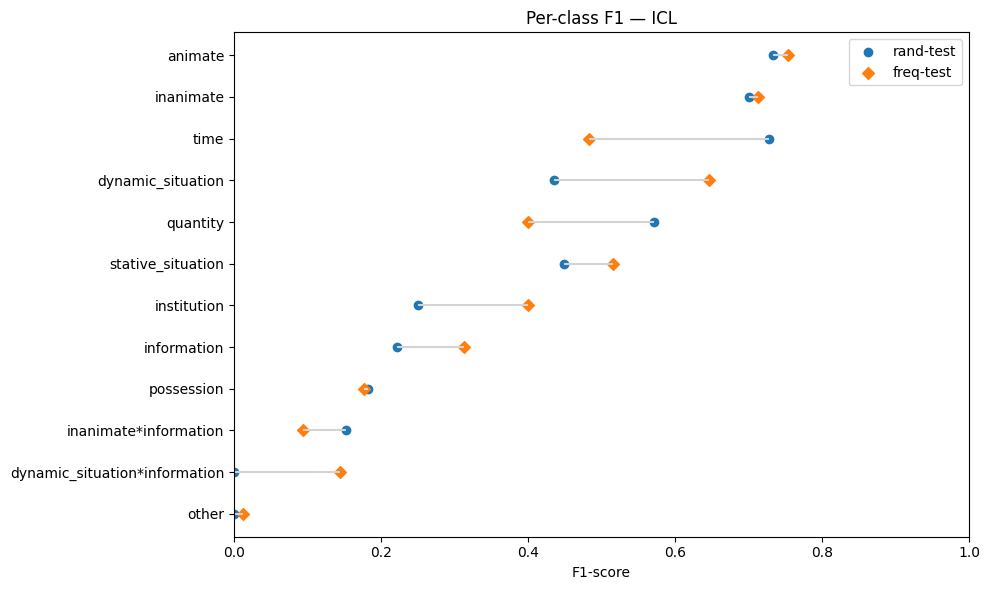

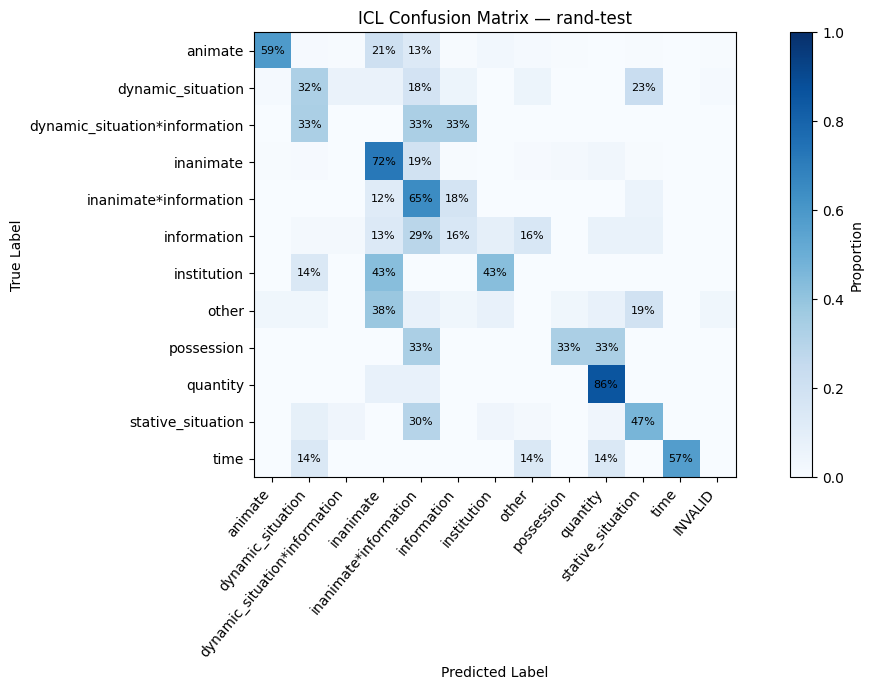

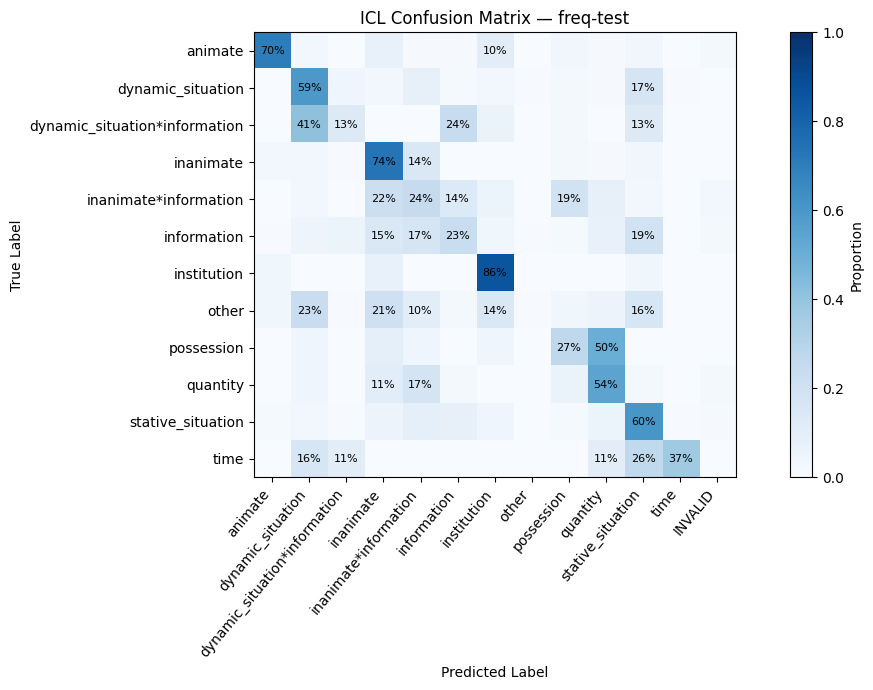

In [ ]:
# ICL Error Analysis — Figures

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score

splits = {
    "rand-test": "rand_test_3shot_lemma",
    "freq-test": "freq_test_3shot_lemma"
}

icl_results, cm_tables, f1_scores = {}, {}, {}

# Calculate per-class F1 and confusion matrices
for split, name in splits.items():
    results = test_results[name].copy()
    results["pred_label"] = results["pred_label"].where(
        results["pred_label"].isin(hypersense_labels), "INVALID"
    )
    icl_results[split] = results

    f1_scores[split] = f1_score(
        results["true_label"], results["pred_label"],
        labels=hypersense_labels, average=None, zero_division=0
    )

    counts = pd.crosstab(
        results["true_label"], results["pred_label"]
    ).reindex(index=hypersense_labels,
              columns=hypersense_labels + ["INVALID"], fill_value=0)

    cm_tables[split] = {
        "counts": counts,
        "normalized": counts.div(counts.sum(axis=1), axis=0).fillna(0)
    }


# Figure 1 — Compare per-class F1 between rand-test and freq-test
f1_table = pd.DataFrame(f1_scores, index=hypersense_labels)
f1_table = f1_table.loc[f1_table.mean(axis=1).sort_values().index]

y = np.arange(len(f1_table))
fig, ax = plt.subplots(figsize=(10, 6))

ax.hlines(y, f1_table["rand-test"], f1_table["freq-test"], color="lightgray")
ax.scatter(f1_table["rand-test"], y, label="rand-test")
ax.scatter(f1_table["freq-test"], y, marker="D", label="freq-test")

ax.set_yticks(y, f1_table.index)
ax.set(xlim=(0, 1), xlabel="F1-score", title="Per-class F1 — ICL")
ax.legend()

plt.tight_layout()
plt.show()


# Figures 2 & 3 — Row-normalized confusion matrices
for split, tables in cm_tables.items():
    cm = tables["normalized"]

    fig, ax = plt.subplots(figsize=(12, 7))
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)

    ax.set_xticks(range(len(cm.columns)), cm.columns, rotation=50, ha="right")
    ax.set_yticks(range(len(cm.index)), cm.index)
    ax.set(xlabel="Predicted Label", ylabel="True Label",
           title=f"ICL Confusion Matrix — {split}")

    # Show percentages for cells representing at least 10% of a class
    for i, j in np.argwhere(cm.to_numpy() >= 0.10):
        ax.text(j, i, f"{cm.iat[i, j]:.0%}", ha="center", va="center", fontsize=8)

    fig.colorbar(im, ax=ax, label="Proportion")
    plt.tight_layout()
    plt.show()

In [ ]:
# ICL Error Analysis — Tables

from sklearn.metrics import classification_report

for split, results in icl_results.items():

    # Precision, Recall, F1, and Support for each class
    print(f"\n{split} — Classification Report")
    report = classification_report(
        results["true_label"], results["pred_label"],
        labels=hypersense_labels, output_dict=True, zero_division=0
    )
    display(pd.DataFrame(report).T.round(4))

    # Number of predictions for each true/predicted label pair
    print(f"\n{split} — Confusion Matrix (Counts)")
    display(cm_tables[split]["counts"])


rand-test — Classification Report


,precision,recall,f1-score,support
animate,0.9771,0.5872,0.7335,218.0
dynamic_situation,0.6579,0.3247,0.4348,77.0
dynamic_situation*information,0.0000,0.0000,0.0000,3.0
inanimate,0.6814,0.7196,0.7000,214.0
inanimate*information,0.0866,0.6471,0.1528,17.0
information,0.3889,0.1556,0.2222,45.0
institution,0.1765,0.4286,0.2500,7.0
other,0.0000,0.0000,0.0000,26.0
possession,0.1250,0.3333,0.1818,3.0
quantity,0.4286,0.8571,0.5714,14.0



rand-test — Confusion Matrix (Counts)


pred_label,animate,dynamic_situation,dynamic_situation*information,inanimate,inanimate*information,information,institution,other,possession,quantity,stative_situation,time,INVALID
true_label,,,,,,,,,,,,,
animate,128,2,1,45,29,1,6,3,1,0,1,0,1
dynamic_situation,1,25,5,5,14,4,0,4,0,0,18,0,1
dynamic_situation*information,0,1,0,0,1,1,0,0,0,0,0,0,0
inanimate,1,2,0,154,41,1,0,2,5,7,1,0,0
inanimate*information,0,0,0,2,11,3,0,0,0,0,1,0,0
information,0,1,1,6,13,7,4,7,0,3,3,0,0
institution,0,1,0,3,0,0,3,0,0,0,0,0,0
other,1,1,0,10,2,1,2,0,1,2,5,0,1
possession,0,0,0,0,1,0,0,0,1,1,0,0,0



freq-test — Classification Report


,precision,recall,f1-score,support
animate,0.8165,0.7008,0.7542,127.0
dynamic_situation,0.7071,0.5949,0.6462,353.0
dynamic_situation*information,0.1622,0.1304,0.1446,46.0
inanimate,0.6914,0.7350,0.7125,317.0
inanimate*information,0.0584,0.2432,0.0942,37.0
information,0.4750,0.2331,0.3128,163.0
institution,0.2609,0.8571,0.4000,28.0
other,0.2500,0.0061,0.0120,163.0
possession,0.1304,0.2727,0.1765,22.0
quantity,0.3165,0.5435,0.4000,46.0



freq-test — Confusion Matrix (Counts)


pred_label,animate,dynamic_situation,dynamic_situation*information,inanimate,inanimate*information,information,institution,other,possession,quantity,stative_situation,time,INVALID
true_label,,,,,,,,,,,,,
animate,89,3,0,9,1,1,13,0,4,1,4,0,2
dynamic_situation,1,210,15,9,28,5,11,2,8,3,59,2,0
dynamic_situation*information,0,19,6,0,0,11,3,0,1,0,6,0,0
inanimate,8,8,2,233,45,0,1,0,6,3,10,0,1
inanimate*information,0,1,0,8,9,5,2,0,7,3,1,0,1
information,1,8,10,24,27,38,6,1,2,12,31,0,3
institution,1,0,0,2,0,0,24,0,0,0,1,0,0
other,6,37,1,34,17,3,23,1,6,9,26,0,0
possession,0,1,0,2,1,0,1,0,6,11,0,0,0


In [ ]:
# ICL Error Analysis — Top Confusion Pairs

for split, matrices in cm_tables.items():
    counts = matrices["counts"]

    # Extract incorrect predictions from the confusion matrix
    errors = counts.stack().rename("Count").reset_index()
    errors.columns = ["True Label", "Predicted Label", "Count"]
    errors = errors[
        (errors["True Label"] != errors["Predicted Label"]) &
        (errors["Count"] > 0)
    ].copy()

    # Percentage of each true class predicted as another label
    errors["Rate (%)"] = (
        errors["Count"] / errors["True Label"].map(counts.sum(axis=1)) * 100
    ).round(2)

    print(f"\n{split} — Top Confusion Pairs")
    display(errors.nlargest(8, "Count"))


rand-test — Top Confusion Pairs


,True Label,Predicted Label,Count,Rate (%)
3,animate,inanimate,45,20.64
43,inanimate,inanimate*information,41,19.16
4,animate,inanimate*information,29,13.30
23,dynamic_situation,stative_situation,18,23.38
17,dynamic_situation,inanimate*information,14,18.18
134,stative_situation,inanimate*information,14,29.79
69,information,inanimate*information,13,28.89
94,other,inanimate,10,38.46



freq-test — Top Confusion Pairs


,True Label,Predicted Label,Count,Rate (%)
23,dynamic_situation,stative_situation,59,16.71
43,inanimate,inanimate*information,45,14.20
92,other,dynamic_situation,37,22.70
94,other,inanimate,34,20.86
75,information,stative_situation,31,19.02
17,dynamic_situation,inanimate*information,28,7.93
69,information,inanimate*information,27,16.56
101,other,stative_situation,26,15.95


In [ ]:
# Extract invalid predictions from both ICL test sets
for split in ["rand_test", "freq_test"]:
    path = f"{output_dir}/icl_v1_{split}_3shot_lemma.csv"
    results = pd.read_csv(path, keep_default_na=False)

    invalid = results[results["pred_label"] == "INVALID"]

    print(f"\n{split}: {len(invalid)} invalid predictions")

    # Display all invalid examples
    display(invalid[["lemma", "definition", "true_label", "raw_output"]])




rand_test: 3 invalid predictions


,lemma,definition,true_label,raw_output
292,écho,Répétition adoucie ou affaiblie d’une ou de pl...,dynamic_situation,sound
311,lessive,"Linge sale qui doit être lessivé, qui a été lavé.",other,possessioin
364,adferme,Cousin germain.,animate,possessioin



freq_test: 10 invalid predictions


,lemma,definition,true_label,raw_output
80,relation,"Lien, rapport d’une chose à une autre.",stative_situation,relation: inanimate*information
248,chimie,Science qui étudie la composition et les réact...,information,science
438,remède,Substance qui sert à guérir un mal ou une mala...,inanimate,possessing
522,sud,Point cardinal opposé au nord ; direction du p...,quantity,direction
699,première,masculin et féminin identiques Élève de cette ...,animate,possessioin
714,cadet,Frère ou sœur par rapport à un frère ou à une ...,animate,possessioin
725,palais,Goût ; sens du goût.,stative_situation,sense
772,forme,"Taxon de bas niveau, placé immédiatement sous ...",information,category: inanimate
775,forme,Élément d’un paradigme morphologique.,information,category: inanimate*information
1011,création,"Ouvrage d’art, composition littéraire.",inanimate*information,possessio


In [ ]:
# Select representative ICL errors from common confusion patterns
results = icl_test_results["rand_test_3shot_lemma"]

error_pairs = [
    ("animate", "inanimate"),
    ("dynamic_situation", "stative_situation"),
    ("inanimate", "inanimate*information")
]

# Display full text in DataFrame columns
pd.set_option("display.max_colwidth", None)
pd.set_option("display.max_columns", None)

for true_label, pred_label in error_pairs:
    # Find examples with this specific classification error
    cases = results[
        (results["true_label"] == true_label) &
        (results["pred_label"] == pred_label)
    ]

    print(f"\n{true_label} → {pred_label}: {len(cases)} errors")

    # Randomly display up to 5 examples for manual analysis
    display(
        cases[["lemma", "definition", "true_label", "pred_label"]]
        .sample(n=min(5, len(cases)), random_state=42)
    )



animate → inanimate: 45 errors


,lemma,definition,true_label,pred_label
438,néllore,Variante de nélore (race de bovins).,animate,inanimate
214,Hubérien,"Habitant de Saint-Pierre-de-Lamy, municipalité québécoise [1].",animate,inanimate
215,Essertinois,"Habitant d’Essertines-en-Châtelneuf, commune française située dans le département de la Loire.",animate,inanimate
500,Medeyrollois,"Habitant de Medeyrolles, commune française située dans le département du Puy-de-Dôme.",animate,inanimate
415,hack,Cheval monté pour surveiller les performances et le comportement des autres chevaux.,animate,inanimate



dynamic_situation → stative_situation: 18 errors


,lemma,definition,true_label,pred_label
1,agroécologie,Pratique ou mode de production agricole appliquant les principes de l’agroécologie.,dynamic_situation,stative_situation
18,tachyarythmie,Combinaison d’une accélération et d’une irrégularité du rythme cardiaque.,dynamic_situation,stative_situation
400,acret,Danger.,dynamic_situation,stative_situation
243,affliction,Grand malheur ; catastrophe.,dynamic_situation,stative_situation
159,ataxie_de_Friedreich,Maladie neurologique évolutive d’origine génétique qui provoque des troubles de l’équilibre.,dynamic_situation,stative_situation



inanimate → inanimate*information: 41 errors


,lemma,definition,true_label,pred_label
508,voisinage,"Espace, lieu ou région qui se trouve à faible distance du point considéré, qu’il soit ou non habité.",inanimate,inanimate*information
314,pinnule,Division ultime des folioles d’une feuille chez les fougères.,inanimate,inanimate*information
168,aimantin,Objet décoratif aimanté.,inanimate,inanimate*information
548,pièce,"Chacun des éléments d’un ensemble défini. → voir pièce détachée, de toutes pièces, juger sur pièces, pièce à pièce et pièce par pièce",inanimate,inanimate*information
110,laque,"Enduit brillant, d’origine industrielle, appliqué sur divers objets.",inanimate,inanimate*information


## PART 3 QLoRA Fine-tuning

We use QLoRA to fine-tune the same 4-bit Qwen3-4B-Instruct model used for ICL. The base model remains frozen, and only the LoRA adapter parameters are updated.

We compare three configurations. Experiments A and B examine the effect of including the lemma, while Experiments A and C compare attention-only adaptation with attention and FFN adaptation.

We select the final configuration using Macro-F1 on `rand-dev` and evaluate it on `rand-test` and `freq-test`. Training and prediction are disabled by default so that saved results can be inspected without additional GPU computation.


In [ ]:
# Install QLoRA libraries only if training or adapter inference is requested.
if RUN_GPU and (RUN_TRAINING or RUN_PREDICTION):
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "--progress-bar", "on", "-v",
                    "bitsandbytes>=0.46.1", "peft", "datasets", "accelerate",
                    "transformers>=4.55,<5"], check=True)
else:
    print("QLoRA: saved-results mode; model packages are not needed.")

QLoRA: saved-results mode; model packages are not needed.


In [ ]:
import gc
import glob
import json
import os

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import display
from sklearn.metrics import accuracy_score, classification_report, f1_score

# These dependencies are needed only for training or adapter inference.
if RUN_GPU and (RUN_TRAINING or RUN_PREDICTION):
    from datasets import Dataset
    from peft import (LoraConfig, PeftModel, get_peft_model,
                      prepare_model_for_kbit_training)
    from tqdm.auto import tqdm
    from transformers import (AutoModelForCausalLM, AutoTokenizer,
                              DataCollatorForSeq2Seq, Trainer, TrainerCallback,
                              TrainingArguments, set_seed)
    set_seed(random_seed)


# Set up result directories for the three QLoRA experiments.
project_dir = str(LORA_DIR)
with_lemma_dir = os.path.join(project_dir, "with_lemma")
definition_only_dir = os.path.join(project_dir, "definition_only")
attention_only_dir = os.path.join(project_dir, "attention_only")

# Create the result directories if they do not already exist.
os.makedirs(with_lemma_dir, exist_ok=True)
os.makedirs(definition_only_dir, exist_ok=True)
os.makedirs(attention_only_dir, exist_ok=True)

print("QLoRA results directory:", project_dir)
print("Training:", "enabled" if RUN_TRAINING else "skipped")
print("Predictions:", "enabled" if RUN_PREDICTION else "skipped")


QLoRA results directory: /content/drive/MyDrive/M2-pariscite/currentnlp/Lab1/QLoRA
Training: skipped
Predictions: skipped


In [ ]:
if RUN_GPU and RUN_TRAINING:
    class FinalStepCallback(TrainerCallback):
        """Evaluate and save at the final training step."""

        def on_step_end(self, args, state, control, **kwargs):
            # Ensure the final step is evaluated and saved.
            if state.global_step == state.max_steps:
                control.should_evaluate = True
                control.should_save = True

            return control

### 3.1 Training Setup and Model Loading

We use the pre-quantized 4-bit Qwen3-4B-Instruct model. The base model remains frozen, and only the LoRA adapter parameters are updated. Experiments A and B adapt both attention and FFN projections, while Experiment C adapts attention projections only. All three experiments use independently initialized adapters with the same training settings: rank 16, alpha 16 (scaling factor 1), and dropout 0.05.

Training uses a batch size of 1 with 8 gradient accumulation steps, giving an effective batch size of 8. Each adapter is trained for one epoch. We evaluate and save checkpoints every 250 optimization steps and at the final step, retaining the checkpoint with the lowest validation loss on `rand-dev` for each experiment.



In [ ]:
if RUN_GPU and RUN_TRAINING:
    # Default LoRA targets: attention and FFN projections (Experiments A and B).
    lora_config = LoraConfig(
        r=16,
        lora_alpha=16,
        lora_dropout=0.05,
        bias="none",
        task_type="CAUSAL_LM",
        target_modules=[
            "q_proj", "k_proj", "v_proj", "o_proj",
            "gate_proj", "up_proj", "down_proj",
        ],
    )
else:
    lora_config = None

def load_trainable_qlora_model(target_modules=None):
    """Load a fresh 4-bit base model and attach an untrained LoRA adapter."""
    set_seed(random_seed)

    tokenizer = AutoTokenizer.from_pretrained(model_identifier)

    # Use the EOS token for padding during training.
    tokenizer.pad_token = tokenizer.eos_token
    tokenizer.padding_side = "right"

    model = AutoModelForCausalLM.from_pretrained(
        model_identifier,
        device_map="auto",
        dtype=torch.float16,
    )

    # Disable caching during training with gradient checkpointing.
    model.config.use_cache = False
    model.config.pad_token_id = tokenizer.pad_token_id

    # Prepare and freeze the quantized base model before adding LoRA.
    model = prepare_model_for_kbit_training(model)

    # Use default LoRA targets unless overridden (Experiment C).
    config = lora_config
    if target_modules is not None:
        config = LoraConfig(
            r=16, lora_alpha=16, lora_dropout=0.05,
            bias="none", task_type="CAUSAL_LM",
            target_modules=target_modules
        )
    model = get_peft_model(model, config)
    model.print_trainable_parameters()

    return model, tokenizer

### 3.2 Data Tokenization and Training

We convert each example into a classification prompt followed by the correct hypersense label and an end-of-sequence token. The prompt tokens are excluded from the loss calculation, so training focuses on predicting the target label.

We then use Hugging Face `Trainer` to train and save each LoRA adapter.


In [ ]:
def tokenize_dataset(dataframe, tokenizer, include_lemma=True, max_length=256):
    """Convert a DataFrame of word senses into a tokenized Hugging Face Dataset.
       Returns input_ids, attention_mask, and labels for QLoRA training.
    """
    dataframe = dataframe.dropna(
        subset=["definition", classification_target]
    ).copy()

    examples = []
    possible_labels = ", ".join(hypersense_labels)

    # Build the classification prompt, optionally including the lemma.
    for _, row in dataframe.iterrows():
        prompt = "Classify this French word sense into one hypersense.\n"

        if include_lemma:
            prompt += f"Lemma: {row['lemma']}\n"

        prompt += (
            f"Definition: {row['definition']}\n"
            f"Possible labels: {possible_labels}"
        )

        prompt = tokenizer.apply_chat_template(
            [
                {"role": "system", "content": "Return only the hypersense label."},
                {"role": "user", "content": prompt},
            ],
            tokenize=False,
            add_generation_prompt=True,
        )

        prompt_ids = tokenizer(
            prompt,
            add_special_tokens=False,
        )["input_ids"]

        answer_ids = tokenizer(
            str(row[classification_target]) + tokenizer.eos_token,
            add_special_tokens=False,
        )["input_ids"]

        # Truncate the prompt from the left while preserving the complete answer.
        max_prompt_length = max_length - len(answer_ids)
        prompt_ids = prompt_ids[-max_prompt_length:]

        input_ids = prompt_ids + answer_ids

        # Exclude prompt tokens from the loss using -100.
        target_ids = [-100] * len(prompt_ids) + answer_ids

        examples.append({
            "input_ids": input_ids,
            "attention_mask": [1] * len(input_ids),
            "labels": target_ids,
        })

    return Dataset.from_list(examples)

In [ ]:
def create_trainer(model, tokenizer, train_dataset, dev_dataset, output_dir):
    """Configure Hugging Face Transformers Trainer for the three QLoRA experiments."""

    # Pad sequences to multiples of 8 and ignore padded labels in the loss.
    data_collator = DataCollatorForSeq2Seq(
        tokenizer=tokenizer,
        model=model,
        padding=True,
        label_pad_token_id=-100,
        pad_to_multiple_of=8,
    )

    training_args = TrainingArguments(
        output_dir=output_dir,
        num_train_epochs=1,

        # Accumulate gradients over 8 batches to obtain an effective batch size of 8.
        per_device_train_batch_size=1,
        per_device_eval_batch_size=1,
        gradient_accumulation_steps=8,

        learning_rate=2e-4,
        warmup_steps=40,
        lr_scheduler_type="cosine",
        eval_strategy="steps",
        eval_steps=250,
        save_strategy="steps",
        save_steps=250,
        save_total_limit=2,

        # Select the checkpoint with the lowest validation loss.
        load_best_model_at_end=True,
        metric_for_best_model="eval_loss",
        greater_is_better=False,

        # Use mixed precision and gradient checkpointing to reduce GPU memory usage.
        fp16=True,
        gradient_checkpointing=True,
        optim="paged_adamw_8bit",
        logging_steps=25,
        report_to="none",
        remove_unused_columns=False,
        seed=random_seed,
    )

    return Trainer(
        model=model,
        args=training_args,
        train_dataset=train_dataset,
        eval_dataset=dev_dataset,
        data_collator=data_collator,
        processing_class=tokenizer,
        # Ensure evaluation and saving also occur at the final training step.
        callbacks=[FinalStepCallback()],
    )


def train_adapter(experiment_dir, include_lemma, target_modules=None):
    """Train an independent QLoRA adapter and return its training summary."""

    # Load a fresh base model and adapter for each experiment.
    model, tokenizer = load_trainable_qlora_model(target_modules)

    train_dataset = tokenize_dataset(train, tokenizer, include_lemma=include_lemma)
    dev_dataset = tokenize_dataset(dev, tokenizer, include_lemma=include_lemma)
    print("Train examples:", len(train_dataset))
    print("Dev examples:", len(dev_dataset))

    # Create the Trainer and start fine-tuning.
    trainer = create_trainer(model, tokenizer, train_dataset, dev_dataset, experiment_dir)
    train_result = trainer.train()

    # Save the best adapter, restored automatically after training.
    best_adapter_dir = os.path.join(experiment_dir, "best_adapter")
    trainer.save_model(best_adapter_dir)
    tokenizer.save_pretrained(best_adapter_dir)
    trainer.save_metrics("train", train_result.metrics)

    summary = {
        "best_checkpoint": trainer.state.best_model_checkpoint,
        "best_validation_loss": trainer.state.best_metric,
        "saved_adapter": best_adapter_dir,
    }
    print(summary)

    # Release memory before training another adapter.
    del trainer, model
    gc.collect()
    torch.cuda.empty_cache()

    return summary


### 3.3 Experiment A: Lemma + Definition (Attention + FFN)

This adapter is trained using both the lemma and definition. After excluding examples with missing definitions or target labels, the training set contains 10,592 examples and `rand-dev` contains 570 examples.


In [ ]:
# Experiment A: Lemma + Definition (Attention + FFN)
if RUN_TRAINING:
    with_lemma_training = train_adapter(
        with_lemma_dir,
        include_lemma=True,
    )
else:
    print("Experiment 1: saved adapter will be used.")

Experiment 1: saved adapter will be used.


### 3.4 Experiment B: Definition Only (Attention + FFN)

This adapter is initialized from a fresh copy of the same base model and trained using definitions only. All other settings remain unchanged, allowing us to examine the effect of including the lemma.

In [ ]:
# Experiment B: Definition Only (Attention + FFN)
if RUN_TRAINING:
    definition_only_training = train_adapter(
        definition_only_dir,
        include_lemma=False,
    )
else:
    print("Experiment 2: saved adapter will be used.")

Experiment 2: saved adapter will be used.


### 3.5 Experiment C: Lemma + Definition (Attention Only)

This adapter uses the same input and training settings as Experiment A, but applies LoRA only to the four attention projections: `q_proj`, `k_proj`, `v_proj`, and `o_proj`.

By comparing Experiments A and C, we examine whether adapting the FFN projections in addition to attention improves classification performance.

In [ ]:
# Experiment C: Lemma + Definition (Attention Only)
if RUN_TRAINING:
    attention_only_training = train_adapter(
        attention_only_dir,
        include_lemma=True,
        target_modules=["q_proj", "k_proj", "v_proj", "o_proj"]
    )
else:
    print("Experiment 3: training skipped.")

Experiment 3: training skipped.


### 3.6 Training Results

The training histories are stored in the saved checkpoints. The following code reads these histories, plots the training and validation loss curves, and saves the figure as `training_curve.png`.

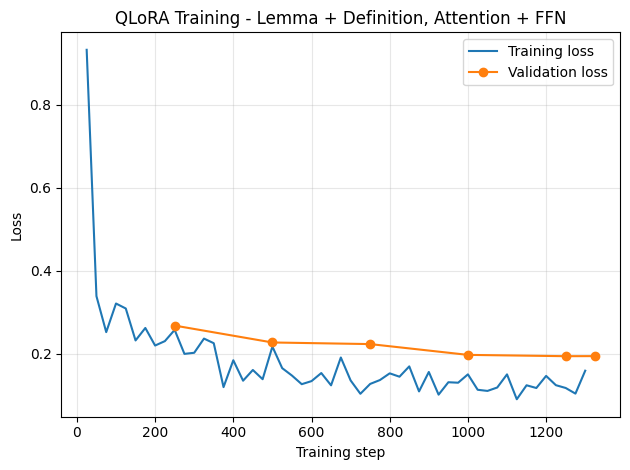

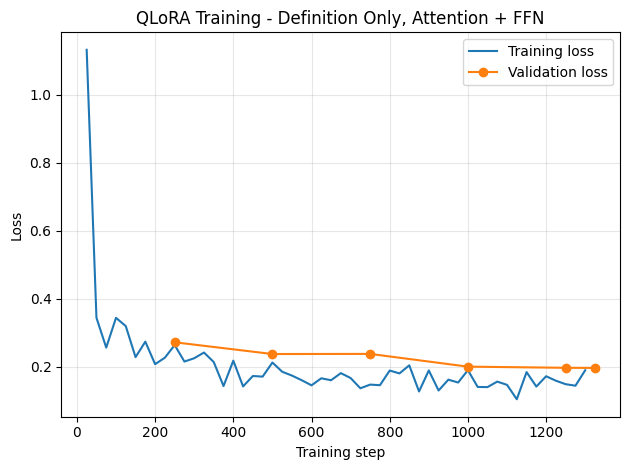

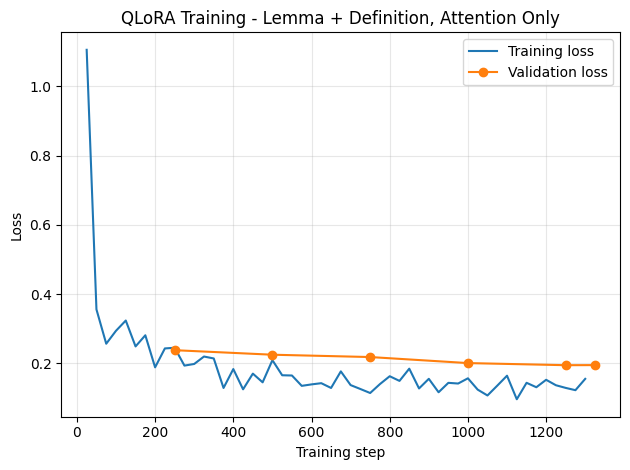

,experiment,latest_checkpoint,best_checkpoint,best_validation_loss,figure
0,"Lemma + definition, Attention + FFN",checkpoint-1324,checkpoint-1250,0.193658,/content/drive/MyDrive/M2-pariscite/currentnlp...
1,"Definition only, Attention + FFN",checkpoint-1324,checkpoint-1324,0.196824,/content/drive/MyDrive/M2-pariscite/currentnlp...
2,"Lemma + definition, Attention only",checkpoint-1324,checkpoint-1250,0.194866,/content/drive/MyDrive/M2-pariscite/currentnlp...


In [ ]:

def load_training_state(experiment_dir):
    """Read the Trainer state from the latest saved checkpoint."""
    checkpoints = glob.glob(os.path.join(experiment_dir, "checkpoint-*"))

    if not checkpoints:
        raise FileNotFoundError(f"No checkpoint found in {experiment_dir}")

    # Select the latest checkpoint by its training step number.
    latest_checkpoint = max(
        checkpoints,
        key=lambda path: int(path.rsplit("-", 1)[-1]),
    )

    state_path = os.path.join(latest_checkpoint, "trainer_state.json")
    with open(state_path, "r") as file:
        state = json.load(file)

    return state, latest_checkpoint


def plot_training_history(experiment_dir, title):
    """Plot and save training and validation loss without loading the model."""
    state, latest_checkpoint = load_training_state(experiment_dir)
    history = pd.DataFrame(state["log_history"])

    # Separate training loss and validation loss records.
    train_history = history.dropna(subset=["loss"]).copy()
    dev_history = history.dropna(subset=["eval_loss"]).copy()

    # Plot both loss curves against optimization steps.
    fig, ax = plt.subplots()
    ax.plot(
        train_history["step"],
        train_history["loss"],
        label="Training loss",
    )
    ax.plot(
        dev_history["step"],
        dev_history["eval_loss"],
        marker="o",
        label="Validation loss",
    )
    ax.set_xlabel("Training step")
    ax.set_ylabel("Loss")
    ax.set_title(title)
    ax.legend()
    ax.grid(alpha=0.3)
    fig.tight_layout()

    # Save the figure in the corresponding experiment directory.
    figure_path = os.path.join(experiment_dir, "training_curve.png")
    fig.savefig(figure_path, dpi=300, bbox_inches="tight")
    plt.show()

    best_checkpoint = os.path.basename(state["best_model_checkpoint"])
    return {
        "latest_checkpoint": os.path.basename(latest_checkpoint),
        "best_checkpoint": best_checkpoint,
        "best_validation_loss": state["best_metric"],
        "figure": figure_path,
    }


# Plot training histories only if all three experiments have saved checkpoints.
if (glob.glob(os.path.join(with_lemma_dir, "checkpoint-*")) and
        glob.glob(os.path.join(definition_only_dir, "checkpoint-*")) and
        glob.glob(os.path.join(attention_only_dir, "checkpoint-*"))):
    training_summaries = pd.DataFrame([
        {
            "experiment": "Lemma + definition, Attention + FFN",
            **plot_training_history(
                with_lemma_dir,
                "QLoRA Training - Lemma + Definition, Attention + FFN",
            ),
        },
        {
            "experiment": "Definition only, Attention + FFN",
            **plot_training_history(
                definition_only_dir,
                "QLoRA Training - Definition Only, Attention + FFN",
            ),
        },
        {
            "experiment": "Lemma + definition, Attention only",
            **plot_training_history(
                attention_only_dir,
                "QLoRA Training - Lemma + Definition, Attention Only",
            ),
        },
    ])

    display(training_summaries)
else:
    training_summaries = pd.DataFrame()
    print(
        "Checkpoint logs missing for at least one experiment: "
        "skipping loss-curve plots; predictions are unaffected."
    )

### 3.7 Prediction and Evaluation Functions

During inference, the prompt does not include the correct label. The generated output is stripped of leading and trailing whitespace and converted to lowercase, then checked against the 12 hypersense labels. Outputs outside this list are marked as `invalid` and counted as errors. We evaluate performance using Accuracy and Macro-F1.

In [ ]:
def load_saved_adapter(adapter_dir):
    """Load a trained LoRA adapter with the 4-bit base model and return the model and tokenizer."""
    tokenizer = AutoTokenizer.from_pretrained(adapter_dir)
    tokenizer.pad_token = tokenizer.eos_token
    tokenizer.padding_side = "right"
    tokenizer.truncation_side = "left"

    # Load the base model and attach the trained LoRA adapter.
    base_model = AutoModelForCausalLM.from_pretrained(
        model_identifier,
        device_map="auto",
        dtype=torch.float16,
    )
    model = PeftModel.from_pretrained(base_model, adapter_dir)

    # Enable caching and evaluation mode for inference.
    model.config.pad_token_id = tokenizer.pad_token_id
    model.config.use_cache = True
    model.eval()

    return model, tokenizer


def predict_dataset(dataframe, model, tokenizer, include_lemma=True, max_length=256):
    """Generate one hypersense prediction for each valid example."""
    eval_data = dataframe.dropna(
        subset=["definition", classification_target]
    ).copy()

    raw_predictions = []
    predictions = []
    possible_labels = ", ".join(hypersense_labels)

    # Keep the inference prompt consistent with training, without revealing the correct label.
    for _, row in tqdm(eval_data.iterrows(), total=len(eval_data)):
        prompt = "Classify this French word sense into one hypersense.\n"

        if include_lemma:
            prompt += f"Lemma: {row['lemma']}\n"

        prompt += (
            f"Definition: {row['definition']}\n"
            f"Possible labels: {possible_labels}"
        )

        prompt = tokenizer.apply_chat_template(
            [
                {"role": "system", "content": "Return only the hypersense label."},
                {"role": "user", "content": prompt},
            ],
            tokenize=False,
            add_generation_prompt=True,
        )

        # Tokenize the prompt and truncate it if necessary.
        inputs = tokenizer(
            prompt,
            return_tensors="pt",
            truncation=True,
            max_length=max_length,
        ).to(model.device)

        # Generate the label using greedy decoding, without computing gradients.
        with torch.inference_mode():
            outputs = model.generate(
                **inputs,
                max_new_tokens=10,
                do_sample=False,
                pad_token_id=tokenizer.pad_token_id,
                eos_token_id=tokenizer.eos_token_id,
            )

        # Extract only the newly generated tokens, excluding the input prompt.
        generated_ids = outputs[0, inputs["input_ids"].shape[1]:]
        raw_prediction = tokenizer.decode(
            generated_ids,
            skip_special_tokens=True,
        )

        # Normalize the output and reject labels outside the allowed set.
        prediction = raw_prediction.strip().lower()

        if prediction not in hypersense_labels:
            prediction = "invalid"

        raw_predictions.append(raw_prediction)
        predictions.append(prediction)

    eval_data["raw_prediction"] = raw_predictions
    eval_data["prediction"] = predictions

    return eval_data


def evaluate_predictions(results):
    """Calculate Accuracy, Macro-F1, and the number of invalid predictions."""
    y_true = results[classification_target]
    y_pred = results["prediction"]

    # Invalid predictions count as errors and are reported separately.
    return {
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(
            y_true,
            y_pred,
            labels=hypersense_labels,
            average="macro",
            zero_division=0,
        ),
        "invalid_predictions": int((y_pred == "invalid").sum()),
    }


def run_and_save_predictions(dataframe, adapter_dir, result_path, include_lemma):
    """Run inference with a saved adapter, save predictions to CSV, and return the results."""
    model, tokenizer = load_saved_adapter(adapter_dir)
    results = predict_dataset(
        dataframe,
        model,
        tokenizer,
        include_lemma=include_lemma,
    )

    # Save predictions for later evaluation and error analysis.
    results.to_csv(result_path, index=False)

    # Release GPU memory after prediction.
    del model
    gc.collect()
    torch.cuda.empty_cache()

    return results

### 3.8 Evaluation on rand-dev and Final Configuration Selection

We evaluate the three QLoRA configurations on `rand-dev` using Accuracy and Macro-F1. We compare their performance and select the final configuration based on Macro-F1.

For each experiment, the checkpoint with the lowest validation loss has already been selected during training. The best configuration is then used for final evaluation on the two test sets.

In [ ]:
# Map each QLoRA experiment to its result directory and lemma setting.
dev_experiments = {
    "A - Attention + FFN (lemma + definition)": (with_lemma_dir, True),
    "B - Attention + FFN (definition)": (definition_only_dir, False),
    "C - Attention only (lemma + definition)": (attention_only_dir, True)
}

# Use saved predictions if available; otherwise run inference when enabled.
for name, (experiment_dir, include_lemma) in dev_experiments.items():
    pred_path = os.path.join(experiment_dir, "rand_dev_predictions.csv")

    if os.path.exists(pred_path):
        print(f"{name}: saved predictions found, skipped.")
    elif RUN_GPU and RUN_PREDICTION:
        print(f"{name}: running inference...")
        run_and_save_predictions(
            dev,
            os.path.join(experiment_dir, "best_adapter"),
            pred_path,
            include_lemma=include_lemma
        )
    else:
        print(f"{name}: predictions not found.")

A - Attention + FFN (lemma + definition): saved predictions found, skipped.
B - Attention + FFN (definition): saved predictions found, skipped.
C - Attention only (lemma + definition): saved predictions found, skipped.


In [ ]:
from safetensors import safe_open
from math import prod

# We count the trainable parameters of each LoRA adapter to compare the efficiency
# of the three configurations, particularly Attention + FFN versus Attention Only.

# Define the saved adapter directories for the three experiments.
experiments = {
    "A - Attention + FFN (lemma + definition)": with_lemma_dir,
    "B - Attention + FFN (definition)": definition_only_dir,
    "C - Attention only (lemma + definition)": attention_only_dir
}

rows = []
for name, folder in experiments.items():
    path = os.path.join(folder, "best_adapter", "adapter_model.safetensors")

    if not os.path.exists(path):
        print(f"{name}: adapter not found")
        continue

    # Count adapter parameters from tensor shapes without loading the model.
    with safe_open(path, framework="pt", device="cpu") as f:
        n_params = sum(prod(f.get_slice(k).get_shape()) for k in f.keys())

    rows.append({
        "Experiment": name,
        "Trainable parameters": n_params,
        "Millions": round(n_params / 1e6, 2)
    })

param_counts = pd.DataFrame(rows)
display(param_counts)

# Save parameter counts for comparing adapter efficiency.
param_counts.to_csv(os.path.join(project_dir, "adapter_parameter_counts.csv"), index=False)

,Experiment,Trainable parameters,Millions
0,A - Attention + FFN (lemma + definition),33030144,33.03
1,B - Attention + FFN (definition),33030144,33.03
2,C - Attention only (lemma + definition),11796480,11.80


In [ ]:
# Load saved rand-dev predictions for the three QLoRA experiments.
dev_files = {
    "Lemma + definition": os.path.join(
        with_lemma_dir, "rand_dev_predictions.csv"
    ),
    "Definition only": os.path.join(
        definition_only_dir, "rand_dev_predictions.csv"
    ),
    "Attention only (lemma + definition)": os.path.join(
        attention_only_dir, "rand_dev_predictions.csv"
    ),
}

dev_results = {}
dev_rows = []

# Calculate evaluation metrics from the saved prediction files.
for experiment, file_path in dev_files.items():
    if not os.path.exists(file_path):
        print(f"Skipped {experiment}: predictions not found.")
        continue

    results = pd.read_csv(file_path)
    dev_results[experiment] = results
    dev_rows.append({
        "input": experiment,
        **evaluate_predictions(results),
    })

# Save and display the development-set comparison.
dev_comparison = pd.DataFrame(dev_rows)
dev_comparison.to_csv(
    os.path.join(project_dir, "dev_comparison.csv"),
    index=False,
)

display(dev_comparison.round(4))

# Select the configuration with the highest Macro-F1 across A, B, and C.
selected_input = dev_comparison.loc[
    dev_comparison["macro_f1"].idxmax(),
    "input",
]

print("Selected configuration:", selected_input)

,input,accuracy,macro_f1,invalid_predictions
0,Lemma + definition,0.8561,0.6462,0
1,Definition only,0.8509,0.6308,0
2,Attention only (lemma + definition),0.8579,0.6312,0


Selected configuration: Lemma + definition


The three QLoRA configurations were evaluated on `rand-dev`.

Experiment A (Lemma + Definition, Attention + FFN) achieved an Accuracy of **0.8561** and a Macro-F1 of **0.6462**. Experiment B (Definition Only, Attention + FFN) achieved **0.8509** and **0.6308**, respectively. Experiment C (Lemma + Definition, Attention Only) achieved **0.8579** and **0.6312**, respectively.

Although Experiment C achieved the highest Accuracy, Experiment A obtained the highest Macro-F1. We therefore selected Experiment A for final evaluation on `rand-test` and `freq-test`.


### 3.9 Final Evaluation on rand-test and freq-test

We evaluate the selected Experiment A (Lemma + Definition, Attention + FFN) adapter on `rand-test` and `freq-test`. Both test sets are reserved for final evaluation and are not used for model selection or hyperparameter tuning.

In [ ]:
# Recreate test predictions with the selected Experiment A adapter when enabled.
if RUN_PREDICTION:
    selected_adapter = os.path.join(with_lemma_dir, "best_adapter")

    run_and_save_predictions(
        rand_test,
        selected_adapter,
        os.path.join(with_lemma_dir, "rand_test_predictions.csv"),
        include_lemma=True,
    )

    run_and_save_predictions(
        freq_test,
        selected_adapter,
        os.path.join(with_lemma_dir, "freq_test_predictions.csv"),
        include_lemma=True,
    )
else:
    print("Prediction skipped: saved test predictions will be used.")


Prediction skipped: saved test predictions will be used.


In [ ]:

# Paths to the saved test predictions from Experiment A.
test_files = {
    "rand-test": os.path.join(with_lemma_dir, "rand_test_predictions.csv"),
    "freq-test": os.path.join(with_lemma_dir, "freq_test_predictions.csv"),
}

test_results = {}
test_rows = []

# Load predictions and calculate evaluation metrics for each test set.
for split_name, file_path in test_files.items():
    results = pd.read_csv(file_path)
    test_results[split_name] = results
    test_rows.append({"split": split_name, **evaluate_predictions(results)})

# Save and display the final test results.
test_metrics = pd.DataFrame(test_rows)
test_metrics.to_csv(os.path.join(with_lemma_dir, "test_metrics.csv"), index=False)

display(test_metrics.round(4))


,split,accuracy,macro_f1,invalid_predictions
0,rand-test,0.8658,0.6985,0
1,freq-test,0.7462,0.6773,0


The selected QLoRA configuration (Experiment A: Lemma + Definition, Attention + FFN) achieved an Accuracy of **0.8658** and a Macro-F1 of **0.6985** on `rand-test`. On `freq-test`, it achieved an Accuracy of **0.7462** and a Macro-F1 of **0.6773**. No invalid predictions were produced on either test set.

### 3.10 QLoRA Error Analysis

We analyse the predictions of the selected Experiment A (Lemma + Definition, Attention + FFN) on `rand-test` and `freq-test`.

As in the ICL experiment, we examine per-class performance, normalized confusion matrices, raw confusion counts, and the most frequent classification errors.

In [ ]:
# Preserve QLoRA evaluation results for later comparison with ICL.
lora_dev_results = dev_results.copy()
lora_test_results = test_results.copy()
lora_test_metrics = test_metrics.copy()

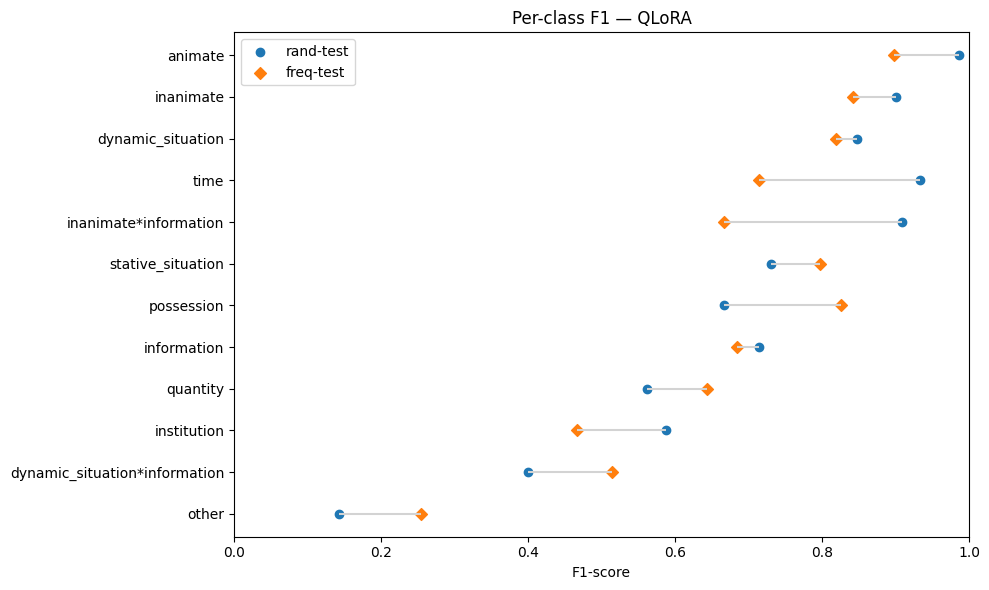

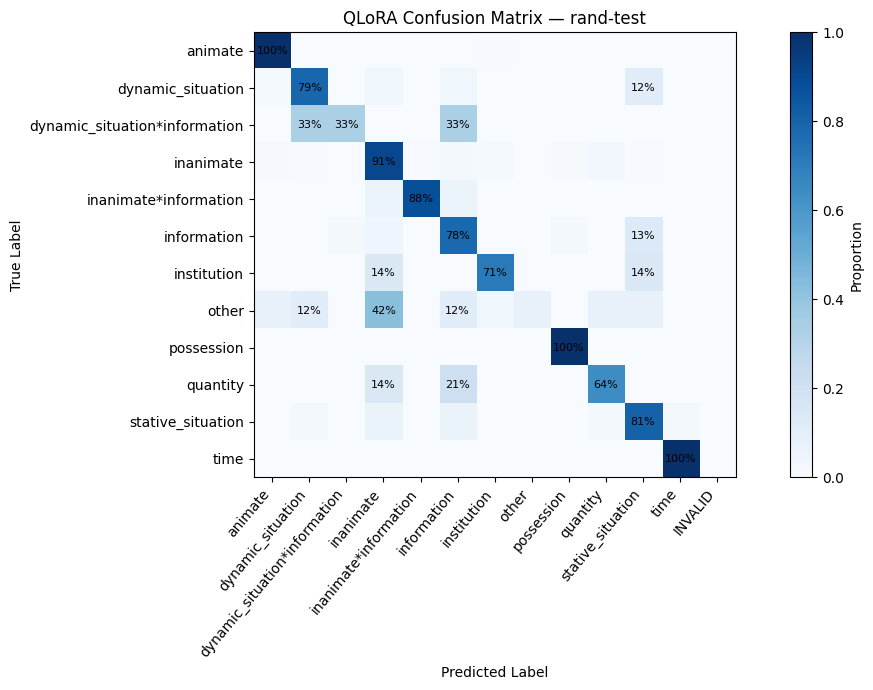

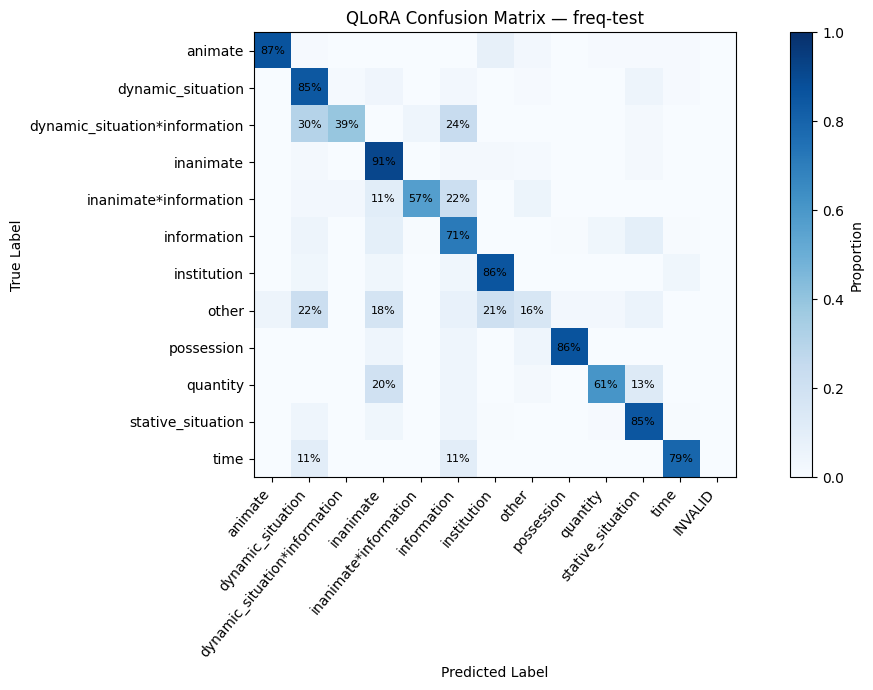

In [ ]:
# QLoRA Error Analysis - Figures

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score

# Load test predictions from the selected Experiment A.
files = {
    "rand-test": LORA_DIR / "with_lemma/rand_test_predictions.csv",
    "freq-test": LORA_DIR / "with_lemma/freq_test_predictions.csv"
}

lora_results, lora_cm, lora_f1 = {}, {}, {}
labels = list(hypersense_labels)

# Calculate per-class F1 and confusion matrices
for split, path in files.items():
    results = pd.read_csv(path)

    # Assign outputs outside the valid label set to INVALID.
    results["prediction"] = results["prediction"].where(
        results["prediction"].isin(labels), "INVALID"
    )
    lora_results[split] = results

    # Compute F1 separately for each hypersense.
    lora_f1[split] = f1_score(
        results["hypersense"], results["prediction"],
        labels=labels, average=None, zero_division=0
    )

    lora_cm[split] = pd.crosstab(
        results["hypersense"], results["prediction"]
    ).reindex(index=labels, columns=labels + ["INVALID"], fill_value=0)


# Figure 1 - Compare per-class F1 between rand-test and freq-test
lora_f1_table = pd.DataFrame(lora_f1, index=labels)

# Sort hypersenses by their average F1 across the two test sets.
lora_f1_table = lora_f1_table.loc[
    lora_f1_table.mean(axis=1).sort_values().index
]

y = np.arange(len(lora_f1_table))
fig, ax = plt.subplots(figsize=(10, 6))

ax.hlines(y, lora_f1_table["rand-test"], lora_f1_table["freq-test"], color="lightgray")
ax.scatter(lora_f1_table["rand-test"], y, label="rand-test")
ax.scatter(lora_f1_table["freq-test"], y, marker="D", label="freq-test")

ax.set_yticks(y, lora_f1_table.index)
ax.set(xlim=(0, 1), xlabel="F1-score", title="Per-class F1 — QLoRA")
ax.legend()

plt.tight_layout()
plt.show()


# Figures 2 & 3 - Row-normalized confusion matrices
for split, counts in lora_cm.items():

    # Divide each row by the total number of examples in that true class.
    cm = counts.div(counts.sum(axis=1), axis=0).fillna(0)

    fig, ax = plt.subplots(figsize=(12, 7))
    im = ax.imshow(cm, cmap="Blues", vmin=0, vmax=1)

    ax.set_xticks(range(len(cm.columns)), cm.columns, rotation=50, ha="right")
    ax.set_yticks(range(len(cm.index)), cm.index)
    ax.set(xlabel="Predicted Label", ylabel="True Label",
           title=f"QLoRA Confusion Matrix — {split}")

    # Show percentages for cells representing at least 10% of a class
    for i, j in np.argwhere(cm.to_numpy() >= 0.10):
        ax.text(j, i, f"{cm.iat[i, j]:.0%}", ha="center", va="center", fontsize=8)

    fig.colorbar(im, ax=ax, label="Proportion")
    plt.tight_layout()
    plt.show()


In [ ]:
# QLoRA Error Analysis — Tables

from sklearn.metrics import classification_report

for split, results in lora_results.items():

    # Report Precision, Recall, F1, and Support for each class.
    print(f"\n{split} — Classification Report")
    report = classification_report(
        results["hypersense"], results["prediction"],
        labels=labels, output_dict=True, zero_division=0
    )
    display(pd.DataFrame(report).T.round(4))

    # Count predictions for each true/predicted label pair.
    counts = lora_cm[split]
    print(f"\n{split} — Confusion Matrix (Counts)")
    display(counts)

    # Extract incorrect predictions, excluding the diagonal.
    errors = counts.stack().rename("Count").reset_index()
    errors.columns = ["True Label", "Predicted Label", "Count"]
    errors = errors[
        (errors["True Label"] != errors["Predicted Label"]) &
        (errors["Count"] > 0)
    ].copy()

    # Calculate each confusion rate relative to the true class size.
    errors["Rate (%)"] = (
        errors["Count"] / errors["True Label"].map(counts.sum(axis=1)) * 100
    ).round(2)

    # Show the eight most frequent confusion pairs.
    print(f"\n{split} — Top Confusion Pairs")
    display(errors.nlargest(8, "Count"))


rand-test — Classification Report


,precision,recall,f1-score,support
animate,0.9775,0.9954,0.9864,218.0000
dynamic_situation,0.9104,0.7922,0.8472,77.0000
dynamic_situation*information,0.5000,0.3333,0.4000,3.0000
inanimate,0.8940,0.9065,0.9002,214.0000
inanimate*information,0.9375,0.8824,0.9091,17.0000
information,0.6604,0.7778,0.7143,45.0000
institution,0.5000,0.7143,0.5882,7.0000
other,1.0000,0.0769,0.1429,26.0000
possession,0.5000,1.0000,0.6667,3.0000
quantity,0.5000,0.6429,0.5625,14.0000



rand-test — Confusion Matrix (Counts)


prediction,animate,dynamic_situation,dynamic_situation*information,inanimate,inanimate*information,information,institution,other,possession,quantity,stative_situation,time,INVALID
hypersense,,,,,,,,,,,,,
animate,217,0,0,0,0,0,1,0,0,0,0,0,0
dynamic_situation,1,61,0,3,0,3,0,0,0,0,9,0,0
dynamic_situation*information,0,1,1,0,0,1,0,0,0,0,0,0,0
inanimate,2,1,0,194,1,4,3,0,2,6,1,0,0
inanimate*information,0,0,0,1,15,1,0,0,0,0,0,0,0
information,0,0,1,2,0,35,0,0,1,0,6,0,0
institution,0,0,0,1,0,0,5,0,0,0,1,0,0
other,2,3,0,11,0,3,1,2,0,2,2,0,0
possession,0,0,0,0,0,0,0,0,3,0,0,0,0



rand-test — Top Confusion Pairs


...

,precision,recall,f1-score,support
animate,0.9322,0.8661,0.8980,127.0000
dynamic_situation,0.7931,0.8470,0.8192,353.0000
dynamic_situation*information,0.7500,0.3913,0.5143,46.0000
inanimate,0.7832,0.9117,0.8426,317.0000
inanimate*information,0.8077,0.5676,0.6667,37.0000
information,0.6591,0.7117,0.6844,163.0000
institution,0.3200,0.8571,0.4660,28.0000
other,0.6341,0.1595,0.2549,163.0000
possession,0.7917,0.8636,0.8261,22.0000
quantity,0.6829,0.6087,0.6437,46.0000



freq-test — Confusion Matrix (Counts)


prediction,animate,dynamic_situation,dynamic_situation*information,inanimate,inanimate*information,information,institution,other,possession,quantity,stative_situation,time,INVALID
hypersense,,,,,,,,,,,,,
animate,110,1,0,0,0,0,10,3,0,1,1,1,0
dynamic_situation,0,299,5,14,1,9,0,4,0,0,17,4,0
dynamic_situation*information,0,14,18,0,2,11,0,0,0,0,1,0,0
inanimate,0,6,0,289,1,5,6,4,0,0,6,0,0
inanimate*information,0,1,1,4,21,8,0,2,0,0,0,0,0
information,0,8,0,15,1,116,0,0,1,6,15,1,0
institution,0,1,0,1,0,1,24,0,0,0,0,1,0
other,8,36,0,29,0,12,34,26,4,4,10,0,0
possession,0,0,0,1,0,1,0,1,19,0,0,0,0



freq-test — Top Confusion Pairs


,True Label,Predicted Label,Count,Rate (%)
92,other,dynamic_situation,36,22.09
97,other,institution,34,20.86
94,other,inanimate,29,17.79
23,dynamic_situation,stative_situation,17,4.82
68,information,inanimate,15,9.20
75,information,stative_situation,15,9.20
16,dynamic_situation,inanimate,14,3.97
27,dynamic_situation*information,dynamic_situation,14,30.43


## PART4 Paired Error Analysis

We align saved predictions for the **same lemma, definition and true label**. This identifies samples where both methods are correct, where only one is correct, or where both fail. A small number of such examples can be discussed in the PDF to explain error patterns. This alignment is based on content rather than raw row indices because the two notebooks filter missing values differently.

In [ ]:
# Compare ICL and QLoRA predictions on the same examples
keys = ["lemma", "definition", "true_label"]

for split in ["rand-test", "freq-test"]:
    icl = icl_results[split][keys + ["pred_label"]].copy()
    lora = lora_results[split].rename(columns={
        "hypersense": "true_label",
        "prediction": "pred_label"
    })[keys + ["pred_label"]].copy()

    # Match examples, including duplicate word senses
    for df in (icl, lora):
        df["dup"] = df.groupby(keys, dropna=False).cumcount()

    paired = icl.merge(lora, on=keys + ["dup"], suffixes=("_icl", "_lora"))

    icl_ok = paired["pred_label_icl"] == paired["true_label"]
    lora_ok = paired["pred_label_lora"] == paired["true_label"]

    # Compare correct predictions and show examples where only QLoRA succeeds
    print(f"\n{split} — {len(paired)} matched examples")
    display(pd.crosstab(icl_ok, lora_ok,
                        rownames=["ICL correct"], colnames=["QLoRA correct"]))

    display(paired.loc[~icl_ok & lora_ok,
                       keys + ["pred_label_icl", "pred_label_lora"]].head(5))


rand-test — 678 matched examples


QLoRA correct,False,True
ICL correct,,
False,80,231
True,11,356


,lemma,definition,true_label,pred_label_icl,pred_label_lora
4,Mardésien,"Habitant de Mardié, commune française située d...",animate,inanimate*information,animate
5,Californais,Habitant de la Californie.,animate,inanimate*information,animate
8,phérormone,Synonyme de phéromone.,inanimate,information,inanimate
16,zéine,Protéine extraite du maïs.,inanimate,inanimate*information,inanimate
17,télougou,Langue dravidienne du sud de l’Inde.,information,other,information



freq-test — 1517 matched examples


QLoRA correct,False,True
ICL correct,,
False,326,425
True,59,707


,lemma,definition,true_label,pred_label_icl,pred_label_lora
4,accessoire,Partie qui n’est pas essentielles à la composi...,inanimate,inanimate*information,inanimate
14,république,Ensemble des territoires régi par les institut...,institution,inanimate,institution
16,tarif,Prix à payer.,possession,quantity,possession
19,fondement,Ce qui sert de base à une thèse ou à une théorie.,information,stative_situation,information
21,rang,Ensemble de soldats alignés les uns à côté des...,animate,dynamic_situation,animate


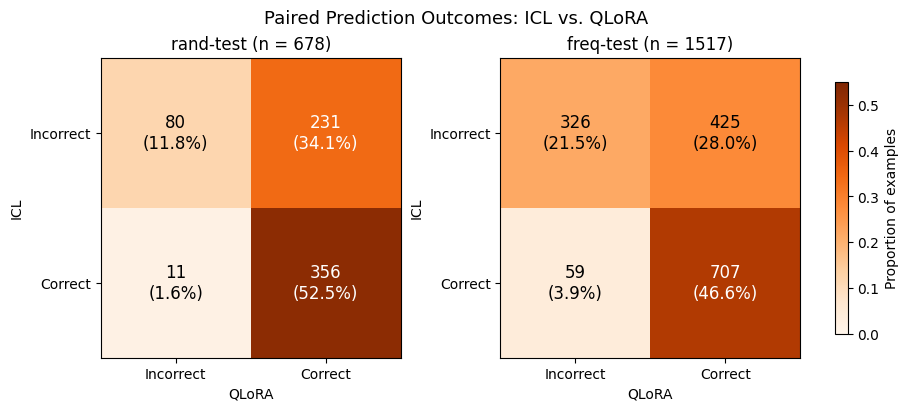

In [ ]:

# Paired Correctness Matrices — ICL vs. QLoRA

import matplotlib.pyplot as plt

keys = ["lemma", "definition", "true_label"]
fig, axes = plt.subplots(1, 2, figsize=(9, 4), constrained_layout=True)

for ax, split in zip(axes, ["rand-test", "freq-test"]):
    icl = icl_results[split][keys + ["pred_label"]].copy()
    lora = lora_results[split].rename(columns={
        "hypersense": "true_label",
        "prediction": "pred_label"
    })[keys + ["pred_label"]].copy()

    # Match the same examples, including duplicates.
    for df in (icl, lora):
        df["dup"] = df.groupby(keys, dropna=False).cumcount()

    paired = icl.merge(lora, on=keys + ["dup"], suffixes=("_icl", "_lora"))

    icl_ok = paired["pred_label_icl"] == paired["true_label"]
    lora_ok = paired["pred_label_lora"] == paired["true_label"]

    # Calculate paired correctness counts and proportions.
    cm = pd.crosstab(icl_ok, lora_ok).reindex(
        index=[False, True], columns=[False, True], fill_value=0
    )
    n = len(paired)
    proportions = cm.to_numpy() / n

    im = ax.imshow(proportions, cmap="Oranges", vmin=0, vmax=0.55)

    # Display counts and percentages inside each cell.
    for i in range(2):
        for j in range(2):
            value = proportions[i, j]
            ax.text(j, i, f"{cm.iloc[i, j]}\n({value:.1%})",
                    ha="center", va="center", fontsize=12,
                    color="white" if value > 0.30 else "black")

    ax.set_xticks([0, 1], ["Incorrect", "Correct"])
    ax.set_yticks([0, 1], ["Incorrect", "Correct"])
    ax.set_xlabel("QLoRA")
    ax.set_ylabel("ICL")
    ax.set_title(f"{split} (n = {n})")

# Shared color scale and figure export.
fig.colorbar(im, ax=axes, shrink=0.8, label="Proportion of examples")
fig.suptitle("Paired Prediction Outcomes: ICL vs. QLoRA", fontsize=13)

figure_path = os.path.join(project_dir, "paired_correctness_matrices.png")
fig.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()